# FAR-Trans wealth banking: which investors will buy again, and whom should the bank contact?

A wealth and retail bank can only contact part of its investor base. This notebook ranks **existing investment customers** of a large European financial institution by the chance that they place **at least one BUY order in the next six months**, and turns the ranking into a contact list.
It reads top to bottom: data gate, cleaning and EDA, snapshot panel and features, out-of-time split, collinearity, class balance, nine models (six single models and three soft-voting ensembles), tuning, calibration, test evaluation with bootstrap intervals, rolling-origin refits, segment analytics, K-Means clusters, explanations, and an optional next-asset appendix.

* **Data**: FAR-Trans (University of Glasgow, CC BY 4.0), 29,090 customers, 806 assets, 388,048 transactions, January 2018 to November 2022. Paper: Sanz-Cruzado, Droukas, McCreadie, *FAR-Trans: An Investment Dataset for Financial Asset Recommendation*, IJCAI 2024 FinRec workshop (arXiv 2407.08692).
* **Task**: at a cut-off date T, for each customer who already has a position or a trade before T, label = 1 if the customer makes at least one BUY in [T, T + 6 months). Features use only data before T.
* **Validation**: out of time. Monthly snapshots; train, validation and test are separated by a six-month purge gap so that no label window of an earlier block reaches into the next block.
* Everything is plain pandas, scikit-learn, XGBoost and LightGBM and lives in this notebook; there is no local package.

In [1]:
import os, json, time, hashlib, warnings, platform, zipfile, urllib.request, math, itertools
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib, xgboost, lightgbm
import xgboost as xgb
import lightgbm as lgb
from sklearn.base import clone
from sklearn.model_selection import ParameterSampler, ParameterGrid, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, silhouette_score)

T0 = time.time()
SEED = 42
SMOKE = os.environ.get("FAR_SMOKE", "0") == "1"            # small sample run to test the notebook end to end
ART = Path(os.environ.get("FAR_ART", "artifacts"))          # everything the app, tests and README read
DATA_DIR = Path(os.environ.get("FAR_DATA", "data"))
for sub in ("figures", "models"):
    (ART / sub).mkdir(parents=True, exist_ok=True)

# search budgets and bootstrap draws (small in the smoke run)
N_ITER = dict(lr=16, dt=15, rf=8, gb=6, xgb=12, lgbm=12) if not SMOKE else dict(lr=2, dt=2, rf=2, gb=2, xgb=2, lgbm=2)
N_BOOT = 1000 if not SMOKE else 100
N_PERM = 5 if not SMOKE else 2
N_SHAP = 5000 if not SMOKE else 500
N_SMOKE_CUST = 4000
GB_SEARCH_FRAC = 0.4 if not SMOKE else 1.0                 # sklearn GB is slow: the search uses a row subsample, the final fit uses all training rows
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
print("smoke run:", SMOKE, "| python", platform.python_version(), "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__)

def save_fig(name):
    plt.tight_layout(); plt.savefig(ART / "figures" / f"{name}.png", dpi=110); plt.show()

def jdump(obj, name):
    (ART / name).write_text(json.dumps(obj, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

smoke run: False | python 3.13.18 | sklearn 1.6.1 | xgboost 3.4.1 | lightgbm 4.6.0


## 1. Data gate: download, provenance and what is simulated

The zip (about 9 MB) is downloaded from the University of Glasgow data repository (record 1658). The notebook stores the SHA-256 of the zip and of every file, row and column counts, and the licence in `artifacts/data_provenance.json`.
**Gate**: the data must support a customer-level, time-split propensity task. That needs (a) dated transactions with a customer id and a Buy/Sell flag, (b) enough customers active across several years, (c) customer attributes. The checks below assert the published counts and the cells after them test (b).

In [2]:
ZIP_URL = "https://researchdata.gla.ac.uk/1658/1/FAR-Trans.zip"
DATA_ZIP = DATA_DIR / "FAR-Trans.zip"
if not DATA_ZIP.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    req = urllib.request.Request(ZIP_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r, open(DATA_ZIP, "wb") as f:
        f.write(r.read())
zip_sha = hashlib.sha256(DATA_ZIP.read_bytes()).hexdigest()
print("zip:", DATA_ZIP.name, f"{DATA_ZIP.stat().st_size/1e6:.1f} MB", "sha256", zip_sha)

zf = zipfile.ZipFile(DATA_ZIP)
files = {}
for info in zf.infolist():
    if info.is_dir():
        continue
    raw_bytes = zf.read(info.filename)
    name = info.filename.split("/")[-1]
    rec = {"bytes": info.file_size, "sha256": hashlib.sha256(raw_bytes).hexdigest()}
    if name.endswith(".csv"):
        head = pd.read_csv(zf.open(info.filename), nrows=5)
        cols = [c if ("prof" + "it") not in c.lower() else "roi_over_full_period (source column name omitted in this listing)" for c in head.columns]
        rec["rows"] = int(raw_bytes.count(b"\n") - 1)                 # data rows, header excluded
        rec["columns"] = cols
    files[name] = rec
    print(f"{name:28s} {rec['bytes']/1e6:8.2f} MB  rows={rec.get('rows','-')}  cols={rec.get('columns','(text file)')}")

def read_csv_zip(name, **kw):
    return pd.read_csv(zf.open(f"FAR-Trans/{name}"), **kw)

tx_raw = read_csv_zip("transactions.csv", parse_dates=["timestamp"])
ci_raw = read_csv_zip("customer_information.csv", parse_dates=["timestamp", "lastQuestionnaireDate"])
ai_raw = read_csv_zip("asset_information.csv")
cp_raw = read_csv_zip("close_prices.csv", parse_dates=["timestamp"])
mk_raw = read_csv_zip("markets.csv")

counts = {
    "customers_with_transactions": int(tx_raw.customerID.nunique()),
    "customers_in_customer_information": int(ci_raw.customerID.nunique()),
    "assets_in_asset_information": int(ai_raw.ISIN.nunique()),
    "assets_traded": int(tx_raw.ISIN.nunique()),
    "transactions": int(len(tx_raw)),
    "buys": int((tx_raw.transactionType == "Buy").sum()),
    "sells": int((tx_raw.transactionType == "Sell").sum()),
    "price_points": int(len(cp_raw)),
    "markets": int(len(mk_raw)),
    "first_transaction_date": str(tx_raw.timestamp.min().date()),
    "last_transaction_date": str(tx_raw.timestamp.max().date()),
    "first_price_date": str(cp_raw.timestamp.min().date()),
    "last_price_date": str(cp_raw.timestamp.max().date()),
}
paper = {"customers": 29090, "assets": 806, "transactions": 388049, "buys": 228913, "sells": 159136, "price_points": 703303,
         "risk_profiles_simulated": 7141, "capacity_estimated": 7318}
print(json.dumps(counts, indent=2))

# customer attributes: latest record per customer; check that attributes never change between a customer's records
last_ci = ci_raw.sort_values("timestamp").groupby("customerID").tail(1).set_index("customerID")
attr_changes = ci_raw.groupby("customerID")[["customerType", "riskLevel", "investmentCapacity"]].nunique().gt(1).sum().to_dict()
n_pred_risk = int(last_ci.riskLevel.str.startswith("Predicted").sum())
n_pred_cap = int(last_ci.investmentCapacity.str.startswith("Predicted").sum())
n_noq = int((last_ci.lastQuestionnaireDate <= "2000-01-01").sum())
print("customers whose segment, risk or capacity changes between records:", attr_changes)
print("customers with a PREDICTED risk level (algorithm-estimated, not from the questionnaire):", n_pred_risk, "| paper: 7,141")
print("customers with a PREDICTED investment capacity:", n_pred_cap, "| paper: 7,318")
print("customers with the 2000-01-01 placeholder questionnaire date (no questionnaire):", n_noq)
print("segment counts:", last_ci.customerType.value_counts().to_dict())

assert counts["customers_with_transactions"] == paper["customers"] and counts["buys"] == paper["buys"]
assert counts["assets_in_asset_information"] == paper["assets"] and counts["price_points"] == paper["price_points"]
assert n_pred_risk == paper["risk_profiles_simulated"] and n_pred_cap == paper["capacity_estimated"]
print("\nrow-count differences against the paper: transactions", counts["transactions"] - paper["transactions"], "| sells", counts["sells"] - paper["sells"],
      "(the file has one row fewer than the paper's headline numbers; not material)")

zip: FAR-Trans.zip 9.8 MB sha256 d0d6cfe027732bab45fdcf9af80eff4fefddc789aedae9bdce0d3d6cfd05cfb6
asset_information.csv            0.08 MB  rows=836  cols=['ISIN', 'assetName', 'assetShortName', 'assetCategory', 'assetSubCategory', 'marketID', 'sector', 'industry', 'timestamp']


close_prices.csv                22.67 MB  rows=703303  cols=['ISIN', 'timestamp', 'closePrice']
customer_information.csv         2.41 MB  rows=32468  cols=['customerID', 'customerType', 'riskLevel', 'investmentCapacity', 'lastQuestionnaireDate', 'timestamp']
limit_prices.csv                 0.06 MB  rows=807  cols=['ISIN', 'minDate', 'maxDate', 'priceMinDate', 'priceMaxDate', 'roi_over_full_period (source column name omitted in this listing)']
markets.csv                      0.01 MB  rows=38  cols=['exchangeID', 'marketID', 'name', 'description', 'country', 'tradingDays', 'tradingHours', 'marketClass']
questionnaires.csv               0.01 MB  rows=175  cols=['Demographics']
README.txt                       0.01 MB  rows=-  cols=(text file)


transactions.csv                35.65 MB  rows=388048  cols=['customerID', 'ISIN', 'transactionID', 'transactionType', 'timestamp', 'totalValue', 'units', 'channel', 'marketID']


{
  "customers_with_transactions": 29090,
  "customers_in_customer_information": 29090,
  "assets_in_asset_information": 806,
  "assets_traded": 320,
  "transactions": 388048,
  "buys": 228913,
  "sells": 159135,
  "price_points": 703303,
  "markets": 38,
  "first_transaction_date": "2018-01-02",
  "last_transaction_date": "2022-11-30",
  "first_price_date": "2018-01-01",
  "last_price_date": "2022-11-29"
}
customers whose segment, risk or capacity changes between records: {'customerType': 0, 'riskLevel': 0, 'investmentCapacity': 0}
customers with a PREDICTED risk level (algorithm-estimated, not from the questionnaire): 7141 | paper: 7,141
customers with a PREDICTED investment capacity: 7318 | paper: 7,318
customers with the 2000-01-01 placeholder questionnaire date (no questionnaire): 7142
segment counts: {'Mass': 18610, 'Premium': 8906, 'Professional': 1327, 'Inactive': 208, 'Legal Entity': 39}

row-count differences against the paper: transactions -1 | sells -1 (the file has one row

**What is simulated or estimated.** Quotes from the dataset README and the paper (arXiv 2407.08692):

* README, `riskLevel`: "Predicted_Conservative / Predicted_Income / Predicted_Balanced / Predicted_Aggressive: Same as earlier, but predicted by an algorithm."
* README, `investmentCapacity`: "Predicted_CAP_...: Same as earlier, but predicted by an algorithm." (the data spell it `Predicted_CAP_LT30K`).
* Paper, risk profile: "In case they have not, the score is simulated through an automated process" ... "A risk profile is estimated following this method for 7,141 investors in our dataset."
* Paper, capacity: "A similar procedure to the one used for risk profile is used for those customers without assessment" ... "(in this case, this is estimated for 7,318 customers)".
* The customer segment (`customerType`) is a bank-assigned label: Mass (under 60k EUR on investments), Premium (over 60k EUR), Professional (sole proprietorship), Legal entity, Inactive. It is not described as simulated.

The counts above reproduce both numbers exactly (7,141 and 7,318), so the `Predicted_` prefix marks the simulated or estimated values. The notebook keeps a flag for each (`risk_predicted`, `cap_predicted`) so the effect can be seen, and an ablation later removes all customer attributes.
**Caveat that cannot be tested here**: segment, risk and capacity never change between a customer's records, so only the final value exists. It is used as a static attribute for every cut-off. The ablation in section 11 shows how much the models rely on these attributes.

In [3]:
prov = {
    "dataset": "FAR-Trans: An Investment Dataset for Financial Asset Recommendation",
    "source_url": "https://researchdata.gla.ac.uk/id/eprint/1658",
    "download_url": ZIP_URL,
    "paper": "Sanz-Cruzado, Droukas, McCreadie. IJCAI-2024 FinRec workshop. arXiv 2407.08692",
    "licence": "CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/)",
    "zip_sha256": zip_sha, "zip_bytes": int(DATA_ZIP.stat().st_size),
    "files": files, "counts": counts, "paper_reported": paper,
    "simulated_or_estimated": {
        "risk_level": {"predicted_values": n_pred_risk, "paper_count": 7141, "marker": "riskLevel starts with 'Predicted_'",
                       "readme_quote": "Predicted_Conservative / Predicted_Income / Predicted_Balanced / Predicted_Aggressive: Same as earlier, but predicted by an algorithm.",
                       "paper_quote": "In case they have not, the score is simulated through an automated process ... A risk profile is estimated following this method for 7,141 investors in our dataset."},
        "investment_capacity": {"predicted_values": n_pred_cap, "paper_count": 7318, "marker": "investmentCapacity starts with 'Predicted_'",
                                "paper_quote": "A similar procedure to the one used for risk profile is used for those customers without assessment ... (in this case, this is estimated for 7,318 customers)"},
        "customer_type": "bank-assigned segment; not described as simulated",
        "static_attributes_note": "segment, risk and capacity never differ between a customer's records, so only one value exists per customer",
    },
    "gate": {"supports_customer_level_time_split_task": True,
             "reasons": ["dated Buy/Sell transactions with customer ids over 59 months", "29,090 customers, 228,913 buys",
                         "customer segment, risk profile and investment capacity attributes", "daily close prices for all assets"],
             "limits": ["the first day of data (2018-01-02) holds about 9% of all rows: opening positions, not trading activity",
                        "trading volume is thin before mid 2019, so snapshots start in October 2019"]},
    "dataset_files_untouched": True,
}
jdump(prov, "data_provenance.json")
print("data_provenance.json written")

data_provenance.json written


## 2. Cleaning and EDA

* Customer attributes: the latest record per customer.
* Assets: some ISINs appear twice in `asset_information.csv`; the latest record is used. Category: Stock, Bond, MTF (mutual fund, called "fund" below).
* **Opening positions.** On 2018-01-02, the first day of data, there are 35,739 rows (about 9% of all rows) for 18,964 customers. This is the portfolio the bank already held, not 18,964 customers deciding to buy on the same morning. These rows count as holdings (what a customer owns) but are **not** counted as trading events in recency, frequency or the label.
* Units times the close price equals `totalValue` for every transaction, so net units times the latest close price gives a market value for a customer's holdings.

In [4]:
assets = ai_raw.sort_values("timestamp").drop_duplicates("ISIN", keep="last").set_index("ISIN")
CAT_CODE = {"Stock": 0, "Bond": 1, "MTF": 2}
CAT_NAME = {0: "stock", 1: "bond", 2: "fund"}

cust = last_ci.copy()
if SMOKE:
    keep_ids = np.random.RandomState(SEED).choice(cust.index.values, N_SMOKE_CUST, replace=False)
    cust = cust.loc[keep_ids]
    tx_raw = tx_raw[tx_raw.customerID.isin(keep_ids)]
    print(f"SMOKE: {len(cust)} customers, {len(tx_raw):,} transactions")
CUST_IDS = np.array(sorted(cust.index))
cust = cust.loc[CUST_IDS]
N = len(CUST_IDS)
cid_map = pd.Series(np.arange(N), index=CUST_IDS)

tx = tx_raw.sort_values(["timestamp", "transactionID"]).reset_index(drop=True)
assert tx.ISIN.isin(assets.index).all()
OPEN_DATE = tx_raw.timestamp.min()
n_open = int((tx.timestamp == OPEN_DATE).sum())
print(f"opening-position rows on {OPEN_DATE.date()}: {n_open:,} ({n_open/len(tx):.1%} of rows), customers {tx[tx.timestamp==OPEN_DATE].customerID.nunique():,}; sells on that day: {int(((tx.timestamp==OPEN_DATE)&(tx.transactionType=='Sell')).sum())}")

ISINS = np.array(sorted(cp_raw.ISIN.unique()))
isin_map = pd.Series(np.arange(len(ISINS)), index=ISINS)
NI = len(ISINS)
assert tx.ISIN.isin(isin_map.index).all()
CAT_OF_ISIN = np.array([CAT_CODE.get(assets.assetCategory.get(i, "Stock"), 0) for i in ISINS])

DAY0 = pd.Timestamp("2018-01-01")
def dayn(t):
    return int((pd.Timestamp(t) - DAY0).days)

CH_CODE = {"Internet Banking": 0, "Branch": 1, "Phone Banking": 2}
A = dict(
    cid=cid_map.loc[tx.customerID].values.astype(np.int64), isn=isin_map.loc[tx.ISIN].values.astype(np.int64),
    buy=(tx.transactionType == "Buy").values, val=tx.totalValue.values.astype(float), units=tx.units.values.astype(float),
    cat=CAT_OF_ISIN[isin_map.loc[tx.ISIN].values], chan=tx.channel.map(CH_CODE).values.astype(np.int64),
    day=((tx.timestamp - DAY0).dt.days.values).astype(np.int64),
    ym=(tx.timestamp.dt.year.values * 12 + tx.timestamp.dt.month.values).astype(np.int64),
    opn=(tx.timestamp == OPEN_DATE).values)
FIRST_DAY = np.full(N, 10**9, dtype=np.int64)
np.minimum.at(FIRST_DAY, A["cid"], A["day"])

# daily close prices on a full calendar, forward filled; PRICE[d - 1, isin] is the close of day number d
cal = pd.date_range(cp_raw.timestamp.min(), cp_raw.timestamp.max(), freq="D")
PRICE = (cp_raw.pivot(index="timestamp", columns="ISIN", values="closePrice").reindex(index=cal, columns=ISINS).ffill()).values.astype(np.float64)
PRICE_DAY0 = dayn(cal[0])
def price_row(t):
    """close prices on the last calendar day strictly before t"""
    i = dayn(t) - 1 - PRICE_DAY0
    return PRICE[int(np.clip(i, 0, len(PRICE) - 1))]
print("price grid:", PRICE.shape, "| missing price share on traded rows:", round(float(np.isnan(PRICE[np.clip(A['day'] - PRICE_DAY0, 0, len(PRICE) - 1), A['isn']]).mean()), 4))

# customer attribute arrays (static)
SEG = cust.customerType.map({"Mass": "Mass", "Premium": "Premium", "Professional": "Professional"}).fillna("Other").values
RISK_MAP = {"Conservative": 0, "Income": 1, "Balanced": 2, "Aggressive": 3}
CAP_MAP = {"CAP_LT30K": 0, "CAP_30K_80K": 1, "CAP_80K_300K": 2, "CAP_GT300K": 3}
risk_core = cust.riskLevel.str.replace("Predicted_", "", regex=False)
cap_core = cust.investmentCapacity.str.replace("Predicted_", "", regex=False)
RISK_ORD = risk_core.map(RISK_MAP).fillna(-1).values
CAP_ORD = cap_core.map(CAP_MAP).fillna(-1).values
RISK_PRED = cust.riskLevel.str.startswith("Predicted").values.astype(float)
CAP_PRED = cust.investmentCapacity.str.startswith("Predicted").values.astype(float)
Q_DAY = np.where(cust.lastQuestionnaireDate.values > np.datetime64("2000-01-01"), (cust.lastQuestionnaireDate - DAY0).dt.days.values, -10**6)
print(pd.crosstab(cust.customerType, cust.riskLevel.str.startswith("Predicted"), rownames=["segment"], colnames=["risk predicted"]).to_string())

opening-position rows on 2018-01-02: 35,739 (9.2% of rows), customers 18,964; sells on that day: 53


price grid: (1794, 807) | missing price share on traded rows: 0.0
risk predicted  False  True 
segment                     
Inactive          141     67
Legal Entity       32      7
Mass            12643   5967
Premium          8064    842
Professional     1069    258


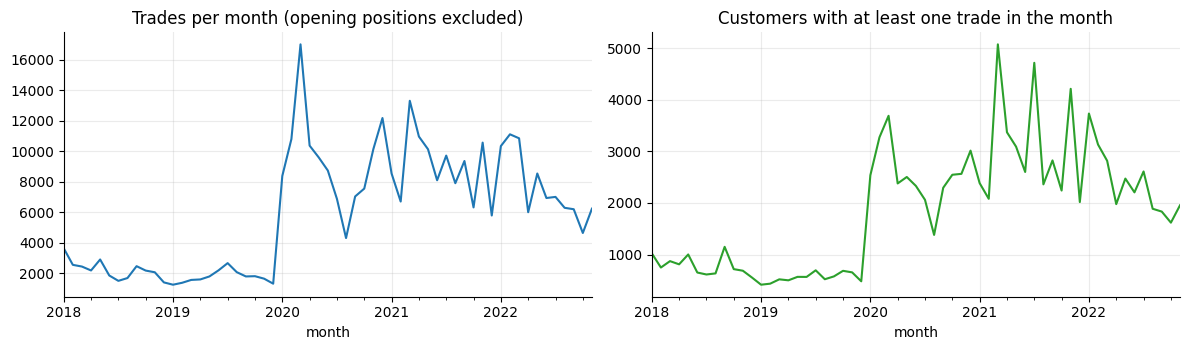

the data are thin before mid 2019 (trades per month in 2018-2019 vs 2020+):
{2018: 2231.0, 2019: 1747.0, 2020: 9418.0, 2021: 8952.0, 2022: 7650.0}


In [5]:
# EDA: activity over time, and the share of customers that buy in the next six months at each month start
mon = pd.DataFrame({"month": tx.timestamp.dt.to_period("M"), "buy": A["buy"], "opn": A["opn"], "cid": A["cid"]})
mon = mon[~mon.opn]
act = mon.groupby("month").agg(trades=("buy", "size"), active_customers=("cid", "nunique"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
act["trades"].plot(ax=ax[0], color="#1f77b4"); ax[0].set_title("Trades per month (opening positions excluded)")
act["active_customers"].plot(ax=ax[1], color="#2ca02c"); ax[1].set_title("Customers with at least one trade in the month")
save_fig("eda_activity")
print("the data are thin before mid 2019 (trades per month in 2018-2019 vs 2020+):")
print(act.groupby(act.index.year).trades.mean().round(0).to_dict())

## 3. Snapshot panel and features

For each cut-off T (the first day of each month) the function below builds one row per **existing customer** (first transaction before T, including the opening position) using only rows dated before T, and four labels:
`y_any` (at least one BUY in [T, T + 6 months)) and `y_stock`, `y_bond`, `y_fund` (a BUY of that asset category).

Feature families (full definitions in `artifacts/feature_dictionary.csv`): recency, frequency and monetary value of past buys and sells (trading events only), net flow trend, holdings (count, distinct categories, market value, concentration, holding period), channel mix, market context of the held assets, tenure, and the static attributes (segment, risk profile, capacity band, questionnaire).
Snapshots start in **October 2019**: before mid 2019 trading data are thin (see the chart above), the share of customers who buy jumps from about 5% to 16% between July and October 2019, and a model trained across that break would learn data coverage rather than behaviour.

In [6]:
def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))

def build_snapshot(T):
    T = pd.Timestamp(T); dT = dayn(T)
    d3, d6, d12 = (dayn(T - pd.DateOffset(months=k)) for k in (3, 6, 12))
    d_end = dayn(T + pd.DateOffset(months=6))
    k = int(np.searchsorted(A["day"], dT))                 # rows dated before T (rows are sorted by date)
    cid, isn, buy, val, units, cat, chan, day, ym, opn = (A[c][:k] for c in ("cid", "isn", "buy", "val", "units", "cat", "chan", "day", "ym", "opn"))
    ev = ~opn
    cnt = lambda m: np.bincount(cid[m], minlength=N).astype(float)
    sm = lambda m, w: np.bincount(cid[m], weights=w[m], minlength=N)
    f = {}
    b, s = ev & buy, ev & ~buy
    f["n_buy_3m"], f["n_buy_6m"], f["n_buy_12m"], f["n_buy_all"] = cnt(b & (day >= d3)), cnt(b & (day >= d6)), cnt(b & (day >= d12)), cnt(b)
    f["n_sell_3m"], f["n_sell_12m"], f["n_sell_all"] = cnt(s & (day >= d3)), cnt(s & (day >= d12)), cnt(s)
    f["buy_val_3m"] = np.log1p(sm(b & (day >= d3), val)); f["buy_val_12m"] = np.log1p(sm(b & (day >= d12), val))
    f["sell_val_12m"] = np.log1p(sm(s & (day >= d12), val))
    nb12 = cnt(b & (day >= d12)); f["avg_buy_val_12m"] = np.log1p(np.where(nb12 > 0, sm(b & (day >= d12), val) / np.maximum(nb12, 1), 0))
    net3 = sm(b & (day >= d3), val) - sm(s & (day >= d3), val)
    m_prev = ev & (day >= d6) & (day < d3)
    netp = sm(m_prev & buy, val) - sm(m_prev & ~buy, val)
    f["net_flow_3m"], f["net_flow_prev3m"] = slog(net3), slog(netp)
    f["net_flow_trend"] = f["net_flow_3m"] - f["net_flow_prev3m"]
    f["buy_count_trend"] = f["n_buy_3m"] - (f["n_buy_6m"] - f["n_buy_3m"])
    gap_fill = dT - dayn(OPEN_DATE)                          # "at least this long": no trade event since the data start
    for nm, m in (("buy", b), ("sell", s), ("trade", ev)):
        last = np.full(N, -1, dtype=np.int64); np.maximum.at(last, cid[m], day[m])
        f[f"days_since_last_{nm}"] = np.where(last >= 0, dT - last, gap_fill).astype(float)
    f["has_trade_event"] = (cnt(ev) > 0).astype(float)
    m12 = ev & (day >= d12)
    f["active_months_12m"] = np.bincount(np.unique(cid[m12].astype(np.int64) * 100000 + ym[m12]) // 100000, minlength=N).astype(float)
    mb12 = b & (day >= d12)
    f["distinct_assets_bought_12m"] = np.bincount(np.unique(cid[mb12] * NI + isn[mb12]) // NI, minlength=N).astype(float)
    n12 = cnt(m12)
    f["share_internet_12m"] = np.where(n12 > 0, np.bincount(cid[m12 & (chan == 0)], minlength=N) / np.maximum(n12, 1), 0)
    f["share_branch_12m"] = np.where(n12 > 0, np.bincount(cid[m12 & (chan == 1)], minlength=N) / np.maximum(n12, 1), 0)
    # holdings: net units per (customer, asset), opening positions included
    key = cid * NI + isn
    ukey, inv = np.unique(key, return_inverse=True)
    net = np.bincount(inv, weights=np.where(buy, units, -units), minlength=len(ukey))
    first_buy = np.full(len(ukey), 10**9, dtype=np.int64); np.minimum.at(first_buy, inv[buy], day[buy])
    held = net > 1e-6
    hk = ukey[held]; h_cid, h_isn, h_units, h_first = hk // NI, hk % NI, net[held], first_buy[held]
    pT, p3, p1 = price_row(T), price_row(T - pd.DateOffset(months=3)), price_row(T - pd.DateOffset(months=1))
    mv = h_units * np.nan_to_num(pT[h_isn])
    nheld = np.bincount(h_cid, minlength=N).astype(float)
    port = np.bincount(h_cid, weights=mv, minlength=N)
    share = np.where(port[h_cid] > 0, mv / np.where(port[h_cid] > 0, port[h_cid], 1), 1.0 / np.maximum(nheld[h_cid], 1))
    f["n_assets_held"] = nheld
    f["n_assets_ever"] = np.bincount(np.unique(key) // NI, minlength=N).astype(float)
    h_cat = CAT_OF_ISIN[h_isn]
    f["n_categories_held"] = sum((np.bincount(h_cid[h_cat == c], minlength=N) > 0).astype(float) for c in range(3))
    f["port_value_log"] = np.log1p(port)
    f["hhi_held"] = np.where(nheld > 0, np.bincount(h_cid, weights=share ** 2, minlength=N), 0)
    top1 = np.zeros(N); np.maximum.at(top1, h_cid, share); f["top1_share"] = top1
    for c in range(3):
        f[f"share_{CAT_NAME[c]}"] = np.bincount(h_cid[h_cat == c], weights=share[h_cat == c], minlength=N)
    f["holding_days_mean"] = np.where(nheld > 0, np.bincount(h_cid, weights=dT - h_first, minlength=N) / np.maximum(nheld, 1), 0)
    for nm, p0 in (("3m", p3), ("1m", p1)):
        r = np.nan_to_num(np.clip(pT[h_isn] / p0[h_isn] - 1, -0.9, 5), nan=0.0, posinf=0.0, neginf=0.0)
        f[f"held_ret_{nm}"] = np.bincount(h_cid, weights=share * r, minlength=N)
    f["tenure_days"] = (dT - FIRST_DAY).astype(float)
    # static attributes
    f["seg_premium"], f["seg_professional"], f["seg_other"] = (SEG == "Premium").astype(float), (SEG == "Professional").astype(float), (SEG == "Other").astype(float)
    f["risk_ord"], f["risk_missing"], f["risk_predicted"] = RISK_ORD.astype(float), (RISK_ORD < 0).astype(float), RISK_PRED
    f["cap_ord"], f["cap_missing"], f["cap_predicted"] = CAP_ORD.astype(float), (CAP_ORD < 0).astype(float), CAP_PRED
    q_ok = (Q_DAY > 0) & (Q_DAY < dT)
    f["questionnaire_done"] = q_ok.astype(float); f["days_since_questionnaire"] = np.where(q_ok, dT - Q_DAY, 0).astype(float)
    # labels: BUY events in [T, T + 6 months)
    wmask = A["buy"] & (A["day"] >= dT) & (A["day"] < d_end)
    lab = {"y_any": np.bincount(A["cid"][wmask], minlength=N) > 0}
    for c in range(3):
        lab[f"y_{CAT_NAME[c]}"] = np.bincount(A["cid"][wmask & (A["cat"] == c)], minlength=N) > 0
    pop = FIRST_DAY < dT
    df = pd.DataFrame({k_: v[pop].astype(np.float32) for k_, v in f.items()})
    df.insert(0, "customerID", CUST_IDS[pop]); df.insert(1, "snapshot", T)
    for k_, v in lab.items():
        df[k_] = v[pop].astype(np.int8)
    return df

FEATURES_ALL = None
t = time.time()
snap_dates = pd.date_range("2019-10-01", "2022-06-01", freq="MS")        # last cut-off whose 6-month window ends on 2022-11-30
panel = pd.concat([build_snapshot(T) for T in snap_dates], ignore_index=True)
META = ["customerID", "snapshot", "y_any", "y_stock", "y_bond", "y_fund"]
FEATURES_ALL = [c for c in panel.columns if c not in META]
assert not panel[FEATURES_ALL].isna().any().any()
panel["snap_id"] = panel.snapshot.rank(method="dense").astype(int) - 1
print(f"panel: {len(panel):,} rows, {panel.customerID.nunique():,} customers, {len(snap_dates)} snapshots, {len(FEATURES_ALL)} features, built in {time.time()-t:.0f}s")
print(panel.groupby("snapshot")[["y_any", "y_stock", "y_bond", "y_fund"]].mean().round(3).iloc[[0, 6, 12, 18, 24, 30, -1]].to_string())

panel: 798,812 rows, 28,568 customers, 33 snapshots, 47 features, built in 3s
            y_any  y_stock  y_bond  y_fund
snapshot                                  
2019-10-01  0.159    0.146   0.008   0.013
2020-04-01  0.159    0.153   0.004   0.005
2020-10-01  0.181    0.152   0.030   0.008
2021-04-01  0.195    0.128   0.065   0.016
2021-10-01  0.186    0.119   0.063   0.019
2022-04-01  0.123    0.096   0.026   0.005
2022-06-01  0.111    0.085   0.026   0.005


### Feature dictionary (plain English)

In [7]:
FD = {
 "tenure_days": ("tenure", "Days from the customer's first record in the data (2018-01-02 for the opening book) to the cut-off T. Left-censored at 2018-01-02."),
 "n_buy_3m": ("frequency", "Number of BUY trades in the 3 months before T (opening positions excluded)."),
 "n_buy_6m": ("frequency", "Number of BUY trades in the 6 months before T."),
 "n_buy_12m": ("frequency", "Number of BUY trades in the 12 months before T."),
 "n_buy_all": ("frequency", "Number of BUY trades since 2018-01-03."),
 "n_sell_3m": ("frequency", "Number of SELL trades in the 3 months before T."),
 "n_sell_12m": ("frequency", "Number of SELL trades in the 12 months before T."),
 "n_sell_all": ("frequency", "Number of SELL trades since 2018-01-03."),
 "buy_val_3m": ("monetary", "Log of 1 + euro value bought in the last 3 months."),
 "buy_val_12m": ("monetary", "Log of 1 + euro value bought in the last 12 months."),
 "sell_val_12m": ("monetary", "Log of 1 + euro value sold in the last 12 months."),
 "avg_buy_val_12m": ("monetary", "Log of 1 + the average euro size of a BUY in the last 12 months (0 if none)."),
 "net_flow_3m": ("trend", "Signed log of (bought minus sold, euros) in the last 3 months."),
 "net_flow_prev3m": ("trend", "Signed log of (bought minus sold, euros) in months 4 to 6 before T."),
 "net_flow_trend": ("trend", "Net flow of the last 3 months minus net flow of the 3 months before that (positive = more buying lately)."),
 "buy_count_trend": ("trend", "BUY count of the last 3 months minus BUY count of months 4 to 6."),
 "days_since_last_buy": ("recency", "Days since the last BUY trade; if there is none, the days since 2018-01-02 (at least that long)."),
 "days_since_last_sell": ("recency", "Days since the last SELL trade (same fill rule)."),
 "days_since_last_trade": ("recency", "Days since the last BUY or SELL trade (same fill rule)."),
 "has_trade_event": ("recency", "1 if the customer has made any trade since 2018-01-03, else 0 (opening book only)."),
 "active_months_12m": ("frequency", "Number of distinct calendar months with at least one trade in the last 12 months."),
 "distinct_assets_bought_12m": ("diversity", "Number of different assets bought in the last 12 months."),
 "share_internet_12m": ("channel", "Share of the last 12 months' trades placed through internet banking."),
 "share_branch_12m": ("channel", "Share of the last 12 months' trades placed in a branch (the rest is phone banking)."),
 "n_assets_held": ("holdings", "Number of assets with a positive net position at T (buys minus sells in units)."),
 "n_assets_ever": ("holdings", "Number of different assets the customer has ever traded or held in the data."),
 "n_categories_held": ("holdings", "Number of asset categories (stock, bond, fund) currently held, 0 to 3."),
 "port_value_log": ("holdings", "Log of 1 + estimated market value of holdings at T (net units times the last close, euros)."),
 "hhi_held": ("concentration", "Concentration of the portfolio: sum of squared value shares of held assets (1 = a single asset)."),
 "top1_share": ("concentration", "Value share of the largest holding."),
 "share_stock": ("holdings", "Share of portfolio value in stocks."),
 "share_bond": ("holdings", "Share of portfolio value in bonds."),
 "share_fund": ("holdings", "Share of portfolio value in mutual funds."),
 "holding_days_mean": ("holdings", "Average days since the first buy of each asset currently held (the opening book counts from 2018-01-02)."),
 "held_ret_3m": ("market context", "Value-weighted 3-month price return of the assets the customer holds, up to T."),
 "held_ret_1m": ("market context", "Value-weighted 1-month price return of the assets the customer holds, up to T."),
 "seg_premium": ("segment", "1 if bank segment is Premium (over 60k EUR on investments); the reference group is Mass."),
 "seg_professional": ("segment", "1 if bank segment is Professional (sole proprietor)."),
 "seg_other": ("segment", "1 if bank segment is Legal entity or Inactive."),
 "risk_ord": ("risk profile", "Risk profile as 0 Conservative, 1 Income, 2 Balanced, 3 Aggressive; -1 if not available. Partly simulated (see predicted flag)."),
 "risk_missing": ("risk profile", "1 if no risk profile is available."),
 "risk_predicted": ("risk profile", "1 if the risk profile was predicted by an algorithm rather than taken from the questionnaire."),
 "cap_ord": ("capacity", "Investment capacity band: 0 under 30k, 1 30-80k, 2 80-300k, 3 over 300k EUR; -1 if not available. Partly estimated."),
 "cap_missing": ("capacity", "1 if no capacity band is available."),
 "cap_predicted": ("capacity", "1 if the capacity band was estimated by an algorithm."),
 "questionnaire_done": ("questionnaire", "1 if a risk questionnaire was completed before T."),
 "days_since_questionnaire": ("questionnaire", "Days from the last questionnaire to T (0 if none before T)."),
}
STATIC = ["seg_premium", "seg_professional", "seg_other", "risk_ord", "risk_missing", "risk_predicted", "cap_ord", "cap_missing", "cap_predicted", "questionnaire_done", "days_since_questionnaire"]
assert set(FD) == set(FEATURES_ALL), set(FEATURES_ALL) ^ set(FD)
DESC = {k: v[1] for k, v in FD.items()}
print(len(FD), "features documented;", len(STATIC), "of them are static customer attributes")

47 features documented; 11 of them are static customer attributes


## 4. Out-of-time split with a purge gap

Every row is one customer at one monthly cut-off. A label looks six months ahead, so a row at cut-off T uses the future up to T + 6 months. Rules:

* **train** cut-offs 2019-10 to 2020-10, **validation** 2021-04 to 2021-06, **test** 2021-12 to 2022-06 (the latest cut-offs whose six-month window is fully observed; the data end on 2022-11-30).
* **Purge gap**: the first cut-off of each block is at least six months after the last cut-off of the block before, so no training label window overlaps the features of the next block (checked by an assertion).
* Train fits models, validation chooses hyper-parameters, the imbalance strategy, calibrator, decision threshold and propensity-band edges, and test is scored once.
* Customers appear in several snapshots, so the bootstrap later resamples **customers**, not rows.

train: last cut-off 2020-10-01 -> label window ends 2021-04-01 <= first valid cut-off 2021-04-01  (gap OK)
valid: last cut-off 2021-06-01 -> label window ends 2021-12-01 <= first test cut-off 2021-12-01  (gap OK)


       snapshots      rows  customers  buyers (y_any=1)  positive rate  stock buy rate  fund buy rate  bond buy rate
train       13.0  278610.0    22708.0           46676.0         0.1675          0.1559         0.0085         0.0084
valid        3.0   74959.0    25126.0           14294.0         0.1907          0.1198         0.0168         0.0689
test         7.0  197513.0    28568.0           26803.0         0.1357          0.1043         0.0074         0.0293


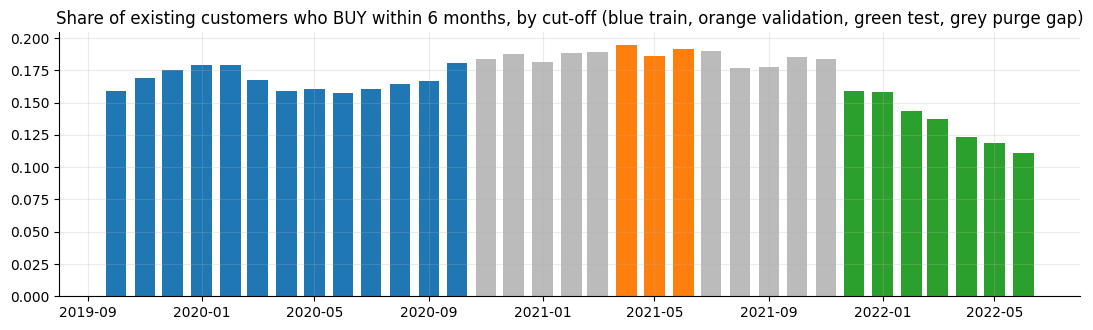

The test period has a lower uptake rate than training: a real out-of-time drift, left in on purpose.


In [8]:
SPLIT_RANGE = {"train": ("2019-10-01", "2020-10-01"), "valid": ("2021-04-01", "2021-06-01"), "test": ("2021-12-01", "2022-06-01")}
def in_range(s, lo, hi):
    return (panel.snapshot >= pd.Timestamp(lo)) & (panel.snapshot <= pd.Timestamp(hi))
panel["split"] = "gap"
for nm, (lo, hi) in SPLIT_RANGE.items():
    panel.loc[in_range(panel.snapshot, lo, hi), "split"] = nm
order = ["train", "valid", "test"]
for a, b in zip(order[:-1], order[1:]):
    last_a = pd.Timestamp(SPLIT_RANGE[a][1]); first_b = pd.Timestamp(SPLIT_RANGE[b][0])
    assert last_a + pd.DateOffset(months=6) <= first_b, (a, b)
    print(f"{a}: last cut-off {last_a.date()} -> label window ends {(last_a + pd.DateOffset(months=6)).date()} <= first {b} cut-off {first_b.date()}  (gap OK)")
assert pd.Timestamp(SPLIT_RANGE["test"][1]) + pd.DateOffset(months=6) <= tx.timestamp.max() + pd.Timedelta(days=1)
Y = "y_any"
TR, VA, TE = (panel[panel.split == s].reset_index(drop=True) for s in order)
ytr, yva, yte = TR[Y].values, VA[Y].values, TE[Y].values

bal = pd.DataFrame({s: {"snapshots": d.snapshot.nunique(), "rows": len(d), "customers": d.customerID.nunique(), "buyers (y_any=1)": int(d[Y].sum()),
                        "positive rate": d[Y].mean(), "stock buy rate": d.y_stock.mean(), "fund buy rate": d.y_fund.mean(), "bond buy rate": d.y_bond.mean()}
                    for s, d in zip(order, (TR, VA, TE))}).T
print(bal.round(4).to_string())
snap_tab = panel.groupby("snapshot").agg(split=("split", "first"), rows=(Y, "size"), customers=("customerID", "nunique"), positives=(Y, "sum"), positive_rate=(Y, "mean")).reset_index()
snap_tab.to_csv(ART / "snapshots.csv", index=False)
bal.reset_index().rename(columns={"index": "split"}).to_csv(ART / "splits.csv", index=False)
jdump({s: {"rows": int(bal.loc[s, "rows"]), "customers": int(bal.loc[s, "customers"]), "positives": int(bal.loc[s, "buyers (y_any=1)"]), "positive_rate": float(bal.loc[s, "positive rate"]),
           "first_cutoff": SPLIT_RANGE[s][0], "last_cutoff": SPLIT_RANGE[s][1]} for s in order}, "class_balance.json")

fig, ax = plt.subplots(figsize=(11, 3.4))
colors = {"train": "#1f77b4", "gap": "#bbbbbb", "valid": "#ff7f0e", "test": "#2ca02c"}
ax.bar(snap_tab.snapshot, snap_tab.positive_rate, width=22, color=snap_tab.split.map(colors))
ax.set_title("Share of existing customers who BUY within 6 months, by cut-off (blue train, orange validation, green test, grey purge gap)")
save_fig("positive_rate_by_snapshot")
print("The test period has a lower uptake rate than training: a real out-of-time drift, left in on purpose.")

## 5. Multicollinearity: Spearman screen and VIF

1. Spearman screen on training rows: for every pair with |rho| > 0.9 the feature with the weaker association with the label is dropped. This set is used by all tree models.
2. For logistic regression only: iterative VIF pruning (drop the largest VIF while it exceeds 10). VIF is the diagonal of the inverse correlation matrix of the winsorised, standardised training features.

In [9]:
samp = TR.sample(min(60000, len(TR)), random_state=SEED)
const = [c for c in FEATURES_ALL if samp[c].std() == 0]
print("constant features dropped:", const)
cols0 = [c for c in FEATURES_ALL if c not in const]
rho = samp[cols0].corr(method="spearman").abs()
tgt = samp[cols0].apply(lambda s: abs(pd.Series(s).corr(samp[Y], method="spearman"))).fillna(0)
pairs = [(rho.loc[a, b], a, b) for i, a in enumerate(cols0) for b in cols0[i + 1:] if rho.loc[a, b] > 0.9]
pairs.sort(reverse=True)
keep = set(cols0); screen_log = []
for r, a, b in pairs:
    if a in keep and b in keep:
        drop = a if tgt[a] < tgt[b] else b
        keep.discard(drop); screen_log.append({"pair": f"{a} ~ {b}", "abs_spearman": round(float(r), 3), "dropped": drop, "kept": b if drop == a else a})
screen_df = pd.DataFrame(screen_log)
TREE_COLS = [c for c in cols0 if c in keep]
print(f"pairs with |rho| > 0.9: {len(pairs)}; features {len(cols0)} -> {len(TREE_COLS)} after the screen")
print(screen_df.to_string(index=False) if len(screen_df) else "none")
screen_df.to_csv(ART / "spearman_screen.csv", index=False)

def vif_of(Z):
    R = np.nan_to_num(np.corrcoef(Z, rowvar=False)); np.fill_diagonal(R, 1.0)       # a column that is constant after winsorising has no correlation
    return np.diag(np.linalg.pinv(R + 1e-8 * np.eye(len(R))))

lo_all, hi_all = samp[TREE_COLS].quantile(0.01).values, samp[TREE_COLS].quantile(0.99).values
Z = np.clip(samp[TREE_COLS].to_numpy(float), lo_all, hi_all)
Z = (Z - Z.mean(0)) / np.where(Z.std(0) == 0, 1, Z.std(0))
vif0 = pd.Series(vif_of(Z), index=TREE_COLS)
cur = list(TREE_COLS); dropped = []
while True:
    keep_idx = [TREE_COLS.index(c) for c in cur]
    v = pd.Series(vif_of(Z[:, keep_idx]), index=cur)
    if v.max() <= 10 or len(cur) <= 5:
        break
    worst = v.idxmax(); dropped.append((worst, float(v.max()))); cur.remove(worst)
LR_COLS = cur
vif_df = pd.DataFrame({"feature": TREE_COLS, "vif_before": vif0.values})
vif_df["vif_after"] = vif_df.feature.map(v)
vif_df["dropped_for_lr"] = vif_df.feature.isin([d[0] for d in dropped])
vif_df["drop_order"] = vif_df.feature.map({d[0]: i + 1 for i, d in enumerate(dropped)})
vif_df = vif_df.sort_values("vif_before", ascending=False)
vif_df.to_csv(ART / "vif_table.csv", index=False)
jdump({"features_before_screen": len(cols0), "after_spearman_screen": len(TREE_COLS), "vif_threshold": 10, "features_dropped_for_lr": [d[0] for d in dropped],
       "features_in_lr": len(LR_COLS), "max_vif_before": float(vif0.max()), "max_vif_after": float(v.max()), "n_vif_gt10_before": int((vif0 > 10).sum()),
       "n_vif_gt10_after": int((v > 10).sum())}, "vif_summary.json")
print("VIF > 10 before:", int((vif0 > 10).sum()), "-> after pruning:", int((v > 10).sum()), "| max after:", round(float(v.max()), 2))
print(vif_df.head(12).round(2).to_string(index=False))
LR_LO, LR_HI = TR[LR_COLS].quantile(0.01).values.astype(float), TR[LR_COLS].quantile(0.99).values.astype(float)
LR_BOUNDS = {c: (float(a), float(b)) for c, a, b in zip(LR_COLS, LR_LO, LR_HI)}
jdump({"columns": LR_COLS, "lo": LR_LO.tolist(), "hi": LR_HI.tolist()}, "lr_clip_bounds.json")
COLS = {"lr": LR_COLS, **{k: TREE_COLS for k in ("dt", "rf", "gb", "xgb", "lgbm")}}

constant features dropped: []


pairs with |rho| > 0.9: 15; features 47 -> 37 after the screen
                                         pair  abs_spearman                    dropped               kept
                        hhi_held ~ top1_share         0.999                 top1_share           hhi_held
       n_buy_12m ~ distinct_assets_bought_12m         0.998 distinct_assets_bought_12m          n_buy_12m
                        n_buy_3m ~ buy_val_3m         0.997                 buy_val_3m           n_buy_3m
                buy_val_12m ~ avg_buy_val_12m         0.996            avg_buy_val_12m        buy_val_12m
                   risk_missing ~ cap_missing         0.996               risk_missing        cap_missing
                      n_buy_12m ~ buy_val_12m         0.992                buy_val_12m          n_buy_12m
                    n_sell_12m ~ sell_val_12m         0.992               sell_val_12m         n_sell_12m
               risk_predicted ~ cap_predicted         0.982             risk_predicted   

VIF > 10 before: 12 -> after pruning: 0 | max after: 9.25
              feature  vif_before  vif_after  dropped_for_lr  drop_order
       net_flow_trend       76.81        NaN            True         1.0
          net_flow_3m       45.43       2.45           False         NaN
          share_stock       40.28        NaN            True         2.0
      net_flow_prev3m       36.55       1.63           False         NaN
           share_fund       28.31       1.44           False         NaN
days_since_last_trade       17.72        NaN            True         3.0
            n_buy_12m       17.23        NaN            True         4.0
    holding_days_mean       12.04       9.04           False         NaN
             n_buy_3m       11.31       7.46           False         NaN
            n_buy_all       10.63       6.43           False         NaN
           n_sell_12m       10.62       9.20           False         NaN
        n_assets_held       10.05       9.25           False      

## 6. Models

Six single models (logistic regression with winsorising and scaling, a shallow decision tree, random forest, scikit-learn gradient boosting, XGBoost, LightGBM) and three **soft-voting ensembles** (the plain average of predicted probabilities): **E1** = LR + RF + GB, **E2** = LR + RF + XGB, **E3** = LR + RF + GB + XGB.
Every model has an untuned starting configuration; a small random search on the **validation** cut-offs (the starting configuration is always one of the candidates) picks the tuned one. Test results are shown for both.

In [10]:
def lr_input(X):
    cols = COLS["lr"]
    return np.clip(X[cols].to_numpy(float), [LR_BOUNDS[c][0] for c in cols], [LR_BOUNDS[c][1] for c in cols])

def make_model(name, p, cw=False):
    if name == "lr":
        pen = p["penalty"]
        return make_pipeline(StandardScaler(), LogisticRegression(penalty=pen, C=p["C"], class_weight=p["class_weight"],
                             solver="liblinear" if pen == "l1" else "lbfgs", max_iter=500, random_state=SEED))
    if name == "dt":
        return DecisionTreeClassifier(max_depth=p["max_depth"], min_samples_leaf=p["min_samples_leaf"], class_weight="balanced" if cw else None, random_state=SEED)
    if name == "rf":
        return RandomForestClassifier(n_estimators=p["n_estimators"], max_depth=p["max_depth"], min_samples_leaf=p["min_samples_leaf"], max_features=p["max_features"],
                                      class_weight="balanced_subsample" if cw else None, n_jobs=-1, random_state=SEED)
    if name == "gb":
        return GradientBoostingClassifier(n_estimators=p["n_estimators"], learning_rate=p["learning_rate"], max_depth=p["max_depth"], subsample=p["subsample"],
                                          min_samples_leaf=p["min_samples_leaf"], random_state=SEED)
    if name == "xgb":
        return xgb.XGBClassifier(n_estimators=p["n_estimators"], learning_rate=p["learning_rate"], max_depth=p["max_depth"], min_child_weight=p["min_child_weight"],
                                 subsample=p["subsample"], colsample_bytree=p["colsample_bytree"], reg_lambda=p["reg_lambda"], tree_method="hist", n_jobs=-1,
                                 random_state=SEED, eval_metric="logloss", scale_pos_weight=(ytr == 0).sum() / (ytr == 1).sum() if cw else 1.0)
    if name == "lgbm":
        return lgb.LGBMClassifier(num_leaves=p["num_leaves"], learning_rate=p["learning_rate"], n_estimators=p["n_estimators"], min_child_samples=p["min_child_samples"],
                                  subsample=p["subsample"], subsample_freq=1, colsample_bytree=p["colsample_bytree"], reg_lambda=p["reg_lambda"], n_jobs=-1,
                                  random_state=SEED, verbose=-1, class_weight="balanced" if cw else None)
    raise KeyError(name)

def _X(name, X):
    return lr_input(X) if name == "lr" else X[COLS[name]]

def fit_model(name, p, X, y, cw=False):
    m = make_model(name, p, cw)
    if name == "gb" and cw:
        m.fit(_X(name, X), y, sample_weight=np.where(y == 1, (y == 0).sum() / max((y == 1).sum(), 1), 1.0))
    else:
        m.fit(_X(name, X), y)
    return m

def proba(m, name, X):
    return m.predict_proba(_X(name, X))[:, 1]

BASE = ["lr", "dt", "rf", "gb", "xgb", "lgbm"]
ENS = {"e1": ["lr", "rf", "gb"], "e2": ["lr", "rf", "xgb"], "e3": ["lr", "rf", "gb", "xgb"]}
NAMES = {"lr": "Logistic regression", "dt": "Decision tree", "rf": "Random forest", "gb": "Gradient boosting", "xgb": "XGBoost", "lgbm": "LightGBM",
         "e1": "Ensemble E1 (LR+RF+GB)", "e2": "Ensemble E2 (LR+RF+XGB)", "e3": "Ensemble E3 (LR+RF+GB+XGB)"}
ALL = BASE + list(ENS)

DEFAULTS = {
    "lr": dict(penalty="l2", C=1.0, class_weight=None),
    "dt": dict(max_depth=3, min_samples_leaf=200),
    "rf": dict(n_estimators=100, max_depth=8, min_samples_leaf=100, max_features="sqrt"),
    "gb": dict(n_estimators=100, learning_rate=0.1, max_depth=3, subsample=1.0, min_samples_leaf=50),
    "xgb": dict(n_estimators=200, learning_rate=0.1, max_depth=4, min_child_weight=1, subsample=1.0, colsample_bytree=1.0, reg_lambda=1.0),
    "lgbm": dict(num_leaves=31, learning_rate=0.1, n_estimators=200, min_child_samples=20, subsample=1.0, colsample_bytree=1.0, reg_lambda=0.0),
}
SPACES = {
    "lr": dict(penalty=["l1", "l2"], C=[0.01, 0.1, 1.0, 10.0], class_weight=[None, "balanced"]),
    "dt": dict(max_depth=[2, 3, 4, 5, 6], min_samples_leaf=[50, 200, 500]),
    "rf": dict(n_estimators=[150, 250], max_depth=[6, 8, 10, 12], min_samples_leaf=[50, 100, 200], max_features=["sqrt", 0.3, 0.5]),
    "gb": dict(n_estimators=[100, 200], learning_rate=[0.05, 0.1], max_depth=[2, 3, 4], subsample=[0.7, 1.0], min_samples_leaf=[50, 200]),
    "xgb": dict(n_estimators=[200, 400], learning_rate=[0.03, 0.05, 0.1], max_depth=[3, 4, 6], min_child_weight=[1, 10, 50], subsample=[0.7, 0.9], colsample_bytree=[0.6, 0.8], reg_lambda=[1.0, 10.0]),
    "lgbm": dict(num_leaves=[15, 31, 63], learning_rate=[0.03, 0.05, 0.1], n_estimators=[200, 400], min_child_samples=[50, 200, 500], subsample=[0.7, 0.9], colsample_bytree=[0.6, 0.8], reg_lambda=[0.0, 10.0]),
}

def quick(y, p):
    return dict(roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p))

print("models:", {k: NAMES[k] for k in ALL}); print("random-search space sizes:", {k: len(list(ParameterGrid(v))) for k, v in SPACES.items()}, "| candidates tried:", N_ITER)

models: {'lr': 'Logistic regression', 'dt': 'Decision tree', 'rf': 'Random forest', 'gb': 'Gradient boosting', 'xgb': 'XGBoost', 'lgbm': 'LightGBM', 'e1': 'Ensemble E1 (LR+RF+GB)', 'e2': 'Ensemble E2 (LR+RF+XGB)', 'e3': 'Ensemble E3 (LR+RF+GB+XGB)'}
random-search space sizes: {'lr': 16, 'dt': 15, 'rf': 72, 'gb': 48, 'xgb': 432, 'lgbm': 432} | candidates tried: {'lr': 16, 'dt': 15, 'rf': 8, 'gb': 6, 'xgb': 12, 'lgbm': 12}


### 6a. Class balance: none vs class_weight vs SMOTE

The positive rate is about 15% to 18% in training: moderately imbalanced, not rare. Three strategies are compared on **validation** with two default-configuration models (logistic regression and LightGBM) on a 100,000-row training sample; SMOTE (written out below, k = 5, balanced 1:1) is applied **inside the training sample only**. Rule fixed in advance: take another strategy only if it beats "none" by at least 0.005 validation PR-AUC (averaged over the two models); otherwise "none" is kept, because re-weighting and over-sampling distort probabilities that the contact-budget and calibration work relies on.

In [11]:
from sklearn.neighbors import NearestNeighbors

def smote(X, y, k=5, seed=SEED):
    """SMOTE: for each synthetic point pick a minority sample, one of its k nearest minority neighbours, and a random point on the segment between them. Balances to 1:1."""
    rs = np.random.RandomState(seed); Xm = X[y == 1]; n_new = int((y == 0).sum() - (y == 1).sum())
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Xm); nbr = nn.kneighbors(Xm, return_distance=False)[:, 1:]
    i = rs.randint(0, len(Xm), n_new); j = nbr[i, rs.randint(0, k, n_new)]
    Xn = Xm[i] + rs.rand(n_new, 1) * (Xm[j] - Xm[i])
    return np.vstack([X, Xn]), np.r_[y, np.ones(n_new, dtype=y.dtype)]

sub_i = np.random.RandomState(SEED).choice(len(TR), min(100000, len(TR)), replace=False)
Xs, ys = TR.iloc[sub_i], ytr[sub_i]
rows = []
for strat in ("none", "class_weight", "smote"):
    for nm in ("lr", "lgbm"):
        if nm == "lr":
            Xa, ya = lr_input(Xs), ys
            if strat == "smote":
                sc = StandardScaler().fit(Xa); Xb, yb = smote(sc.transform(Xa), ya)             # SMOTE on the scaled training sample only
                m = LogisticRegression(C=1.0, max_iter=500).fit(Xb, yb); pv = m.predict_proba(sc.transform(lr_input(VA)))[:, 1]
            else:
                m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=500, class_weight="balanced" if strat == "class_weight" else None)).fit(Xa, ya)
                pv = m.predict_proba(lr_input(VA))[:, 1]
        else:
            Xa, ya = Xs[TREE_COLS].to_numpy(float), ys
            if strat == "smote":
                Xa, ya = smote(Xa, ya)
            m = make_model("lgbm", DEFAULTS["lgbm"], cw=(strat == "class_weight")).fit(Xa, ya); pv = m.predict_proba(VA[TREE_COLS].to_numpy(float))[:, 1]
        top = pv >= np.quantile(pv, 0.8)
        rows.append(dict(strategy=strat, model=NAMES[nm], val_roc_auc=roc_auc_score(yva, pv), val_pr_auc=average_precision_score(yva, pv),
                         val_capture_20=yva[top].sum() / yva.sum(), val_brier=brier_score_loss(yva, pv), mean_predicted=pv.mean()))
imb = pd.DataFrame(rows)
print(imb.round(4).to_string(index=False))
agg = imb.groupby("strategy").val_pr_auc.mean()
best = agg.idxmax()
STRATEGY = best if (agg[best] - agg["none"]) >= 0.005 else "none"
print("\nmean validation PR-AUC:", agg.round(4).to_dict(), "| chosen strategy:", STRATEGY)
assert STRATEGY in ("none", "class_weight"), "SMOTE would need to be added to every model pipeline"
USE_CW = STRATEGY == "class_weight"
imb.to_csv(ART / "imbalance_comparison.csv", index=False)
jdump({"positive_rate_train": float(ytr.mean()), "chosen": STRATEGY, "rule": "other strategy only if validation PR-AUC gain >= 0.005 over none", "mean_val_pr_auc": agg.to_dict()}, "imbalance_decision.json")

    strategy               model  val_roc_auc  val_pr_auc  val_capture_20  val_brier  mean_predicted
        none Logistic regression       0.8883      0.6781          0.5990     0.1051          0.1943
        none            LightGBM       0.9085      0.7189          0.6492     0.0939          0.2097
class_weight Logistic regression       0.8888      0.6749          0.5974     0.1411          0.3403
class_weight            LightGBM       0.9069      0.7177          0.6528     0.1312          0.3392
       smote Logistic regression       0.8871      0.6693          0.5950     0.1418          0.3373
       smote            LightGBM       0.8931      0.6950          0.6242     0.1018          0.2277

mean validation PR-AUC: {'class_weight': 0.6963, 'none': 0.6985, 'smote': 0.6821} | chosen strategy: none


### 6b. Tuning on validation, untuned vs tuned

In [12]:
def tune(name, n_iter, search_frac=1.0):
    space = SPACES[name]
    grid = list(ParameterGrid(space))
    cand = list(ParameterSampler(space, n_iter, random_state=SEED)) if n_iter < len(grid) else grid
    if DEFAULTS[name] not in cand:
        cand = [DEFAULTS[name]] + cand
    if search_frac < 1.0:
        idx = np.random.RandomState(SEED).rand(len(TR)) < search_frac
        Xa, ya = TR[idx], ytr[idx]
    else:
        Xa, ya = TR, ytr
    out = []
    for p in cand:
        t = time.time(); m = fit_model(name, p, Xa, ya, USE_CW and name != "lr"); pv = proba(m, name, VA)
        q = quick(yva, pv); out.append({**{k: str(v) for k, v in p.items()}, "val_roc_auc": q["roc_auc"], "val_pr_auc": q["pr_auc"], "fit_seconds": round(time.time() - t, 1), "_p": p})
    res = pd.DataFrame(out)
    best_p = res.loc[res.val_roc_auc.idxmax(), "_p"]
    res.drop(columns="_p").sort_values("val_roc_auc", ascending=False).to_csv(ART / f"tuning_{name}.csv", index=False)
    return best_p, res.drop(columns="_p")

BEST, TUNE_TABLES = {}, {}
for nm in BASE:
    t = time.time()
    BEST[nm], TUNE_TABLES[nm] = tune(nm, N_ITER[nm], GB_SEARCH_FRAC if nm == "gb" else 1.0)
    print(f"{NAMES[nm]:20s} {len(TUNE_TABLES[nm])} candidates in {time.time()-t:4.0f}s | best val ROC-AUC {TUNE_TABLES[nm].val_roc_auc.max():.4f} | {BEST[nm]}")
jdump({"defaults": DEFAULTS, "tuned": BEST, "strategy": STRATEGY}, "best_params.json")

Logistic regression  16 candidates in   51s | best val ROC-AUC 0.8900 | {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l1'}


Decision tree        15 candidates in   24s | best val ROC-AUC 0.8631 | {'max_depth': 2, 'min_samples_leaf': 50}


Random forest        9 candidates in  326s | best val ROC-AUC 0.8972 | {'n_estimators': 150, 'min_samples_leaf': 200, 'max_features': 'sqrt', 'max_depth': 6}


Gradient boosting    7 candidates in  357s | best val ROC-AUC 0.8970 | {'subsample': 1.0, 'n_estimators': 200, 'min_samples_leaf': 50, 'max_depth': 4, 'learning_rate': 0.1}


XGBoost              13 candidates in   73s | best val ROC-AUC 0.9095 | {'subsample': 0.7, 'reg_lambda': 1.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


LightGBM             13 candidates in   88s | best val ROC-AUC 0.9104 | {'subsample': 0.7, 'reg_lambda': 0.0, 'num_leaves': 31, 'n_estimators': 200, 'min_child_samples': 50, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


In [13]:
# final fits on all training rows: untuned and tuned; predictions on validation and test
MODELS, PV, PT, PVU, PTU, FIT_S = {}, {}, {}, {}, {}, {}
for nm in BASE:
    mu = fit_model(nm, DEFAULTS[nm], TR, ytr, USE_CW and nm != "lr")
    PVU[nm], PTU[nm] = proba(mu, nm, VA), proba(mu, nm, TE)
    t = time.time(); m = fit_model(nm, BEST[nm], TR, ytr, USE_CW and nm != "lr"); FIT_S[nm] = time.time() - t
    MODELS[nm] = m; PV[nm], PT[nm] = proba(m, nm, VA), proba(m, nm, TE)
for e, parts in ENS.items():
    PV[e] = np.mean([PV[p] for p in parts], axis=0); PT[e] = np.mean([PT[p] for p in parts], axis=0)
    PVU[e] = np.mean([PVU[p] for p in parts], axis=0); PTU[e] = np.mean([PTU[p] for p in parts], axis=0)
gain = pd.DataFrame([{"model": NAMES[k], "val_roc_auc_untuned": roc_auc_score(yva, PVU[k]), "val_roc_auc_tuned": roc_auc_score(yva, PV[k]),
                      "test_roc_auc_untuned": roc_auc_score(yte, PTU[k]), "test_roc_auc_tuned": roc_auc_score(yte, PT[k]),
                      "test_pr_auc_untuned": average_precision_score(yte, PTU[k]), "test_pr_auc_tuned": average_precision_score(yte, PT[k])} for k in ALL])
gain["test_roc_auc_gain"] = gain.test_roc_auc_tuned - gain.test_roc_auc_untuned
gain.to_csv(ART / "tuning_gain.csv", index=False)
print(gain.round(4).to_string(index=False))
BEST_SINGLE = max(BASE, key=lambda k: roc_auc_score(yva, PV[k]))
BEST_ENS = max(ENS, key=lambda k: roc_auc_score(yva, PV[k]))
BEST_ALL = max(ALL, key=lambda k: roc_auc_score(yva, PV[k]))
print("selected on VALIDATION ROC-AUC -> best single:", NAMES[BEST_SINGLE], "| best ensemble:", NAMES[BEST_ENS], "| best overall:", NAMES[BEST_ALL])

                     model  val_roc_auc_untuned  val_roc_auc_tuned  test_roc_auc_untuned  test_roc_auc_tuned  test_pr_auc_untuned  test_pr_auc_tuned  test_roc_auc_gain
       Logistic regression               0.8883             0.8900                0.9067              0.9064               0.6745             0.6715            -0.0003
             Decision tree               0.8512             0.8631                0.8796              0.8690               0.5854             0.4957            -0.0107
             Random forest               0.8967             0.8972                0.9134              0.9125               0.7007             0.6994            -0.0009
         Gradient boosting               0.8972             0.9100                0.9130              0.9146               0.6953             0.6990             0.0016
                   XGBoost               0.9063             0.9095                0.9154              0.9157               0.7001             0.6998            

selected on VALIDATION ROC-AUC -> best single: LightGBM | best ensemble: Ensemble E3 (LR+RF+GB+XGB) | best overall: LightGBM


## 7. Calibration, threshold and test evaluation

* **Calibration**: Platt scaling (logistic fit on the logit of the raw probability) against isotonic regression, chosen per model by 5-fold Brier score **inside the validation set** (folds grouped by customer), then fitted on all validation rows. Raw ensemble probabilities are the plain average of the raw component probabilities.
* **Threshold**: the raw probability that maximises F1 on validation, applied unchanged to test.
* **Contact budget metrics**: customers are ranked **within each cut-off** and the top 10%, 20% or 30% are "contacted"; capture is the share of that cut-off's eventual buyers who were in the contacted list, pooled over the test cut-offs.
* **Intervals**: paired bootstrap, 1,000 resamples of **customers** (all of a customer's cut-off rows move together), the same resample for every model.

In [14]:
def top_masks(score, snap, qs, tie):
    """boolean masks marking the top q share of rows inside each snapshot (ties broken at random through `tie`)"""
    order = np.lexsort((tie, -score, snap))
    ss = snap[order]
    start = np.r_[0, np.flatnonzero(np.diff(ss)) + 1]
    counts = np.diff(np.r_[start, len(order)])
    pos_in = np.arange(len(order)) - np.repeat(start, counts)
    n_in = np.repeat(counts, counts)
    out = {}
    for q in qs:
        m = np.empty(len(order), bool); m[order] = pos_in < np.ceil(q * n_in); out[q] = m
    return out

def capture_curve(score, y, snap, tie, qs):
    order = np.lexsort((tie, -score, snap)); ss = snap[order]
    start = np.r_[0, np.flatnonzero(np.diff(ss)) + 1]; counts = np.diff(np.r_[start, len(order)])
    pos_in = np.arange(len(order)) - np.repeat(start, counts); n_in = np.repeat(counts, counts)
    ys = y[order]; cap, prec = [], []
    for q in qs:
        sel = pos_in < np.ceil(q * n_in)
        cap.append(ys[sel].sum() / ys.sum()); prec.append(ys[sel].mean())
    return np.array(cap), np.array(prec)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def fit_cal(p, y, kind):
    if kind == "platt":
        m = LogisticRegression(C=1e6, max_iter=500).fit(logit(p)[:, None], y)
        return {"kind": "platt", "a": float(m.coef_[0, 0]), "b": float(m.intercept_[0])}
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, y)
    return {"kind": "isotonic", "x": iso.X_thresholds_.tolist(), "y": iso.y_thresholds_.tolist()}

def apply_cal(c, p):
    if c["kind"] == "platt":
        return 1 / (1 + np.exp(-(c["a"] * logit(p) + c["b"])))
    return np.interp(p, c["x"], c["y"])

CAL, CAL_CV = {}, []
gkf = GroupKFold(n_splits=5)
for k in ALL:
    cv = {"platt": [], "isotonic": []}
    for a, b in gkf.split(VA, groups=VA.customerID.values):
        for kind in cv:
            c = fit_cal(PV[k][a], yva[a], kind); cv[kind].append(brier_score_loss(yva[b], apply_cal(c, PV[k][b])))
    pick = min(cv, key=lambda z: np.mean(cv[z]))
    CAL[k] = fit_cal(PV[k], yva, pick)
    CAL_CV.append({"model": NAMES[k], "brier_raw_val": brier_score_loss(yva, PV[k]), "cv_brier_platt": np.mean(cv["platt"]), "cv_brier_isotonic": np.mean(cv["isotonic"]), "chosen": pick})
cal_cv = pd.DataFrame(CAL_CV); print(cal_cv.round(5).to_string(index=False))
jdump(CAL, "calibration.json"); cal_cv.to_csv(ART / "calibration_choice.csv", index=False)

THR = {}
for k in ALL:
    pr, rc, th = precision_recall_curve(yva, PV[k]); f1 = 2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-12)
    THR[k] = float(th[np.argmax(f1)])
jdump(THR, "thresholds.json")

snap_te = TE.snap_id.values; tie_te = np.random.RandomState(SEED).rand(len(TE))
PTC = {k: apply_cal(CAL[k], PT[k]) for k in ALL}
PVC = {k: apply_cal(CAL[k], PV[k]) for k in ALL}

def full_metrics(y, p_raw, p_cal, snap, tie, thr):
    fpr, tpr, _ = roc_curve(y, p_raw)
    m = top_masks(p_raw, snap, (0.1, 0.2, 0.3), tie)
    pred = p_raw >= thr; tp = int((pred & (y == 1)).sum())
    prec = tp / max(pred.sum(), 1); rec = tp / y.sum()
    return dict(roc_auc=roc_auc_score(y, p_raw), pr_auc=average_precision_score(y, p_raw), ks=float(np.max(tpr - fpr)),
                brier=brier_score_loss(y, p_cal), brier_raw=brier_score_loss(y, p_raw), threshold=thr, precision=prec, recall=rec,
                f1=2 * prec * rec / max(prec + rec, 1e-12), top_decile_precision=y[m[0.1]].mean(), lift_top_decile=y[m[0.1]].mean() / y.mean(),
                capture_10=y[m[0.1]].sum() / y.sum(), capture_20=y[m[0.2]].sum() / y.sum(), capture_30=y[m[0.3]].sum() / y.sum(), precision_20=y[m[0.2]].mean())

test_rows = [{"model": NAMES[k], "key": k, **full_metrics(yte, PT[k], PTC[k], snap_te, tie_te, THR[k])} for k in ALL]
test_metrics = pd.DataFrame(test_rows)
tie_va = np.random.RandomState(SEED + 1).rand(len(VA))
val_metrics = pd.DataFrame([{"model": NAMES[k], "key": k, **full_metrics(yva, PV[k], PVC[k], VA.snap_id.values, tie_va, THR[k])} for k in ALL])
test_metrics.to_csv(ART / "test_metrics.csv", index=False); val_metrics.to_csv(ART / "val_metrics.csv", index=False)
show = ["model", "roc_auc", "pr_auc", "ks", "brier", "precision", "recall", "f1", "top_decile_precision", "lift_top_decile", "capture_10", "capture_20", "capture_30"]
print("TEST (7 cut-offs, 2021-12 to 2022-06), positive rate", round(float(yte.mean()), 4))
print(test_metrics[show].round(4).to_string(index=False))

                     model  brier_raw_val  cv_brier_platt  cv_brier_isotonic   chosen
       Logistic regression        0.13906         0.09951            0.09650 isotonic
             Decision tree        0.10596         0.10474            0.10061 isotonic
             Random forest        0.09675         0.09660            0.09240 isotonic
         Gradient boosting        0.09324         0.09129            0.08966 isotonic
                   XGBoost        0.09349         0.09128            0.08990 isotonic
                  LightGBM        0.09282         0.09084            0.08974 isotonic
    Ensemble E1 (LR+RF+GB)        0.10019         0.09442            0.09195 isotonic
   Ensemble E2 (LR+RF+XGB)        0.10042         0.09446            0.09200 isotonic
Ensemble E3 (LR+RF+GB+XGB)        0.09761         0.09346            0.09123 isotonic


TEST (7 cut-offs, 2021-12 to 2022-06), positive rate 0.1357
                     model  roc_auc  pr_auc     ks  brier  precision  recall     f1  top_decile_precision  lift_top_decile  capture_10  capture_20  capture_30
       Logistic regression   0.9064  0.6715 0.6347 0.0778     0.3613  0.8697 0.5106                0.6960           5.1287      0.5130      0.7270      0.8481
             Decision tree   0.8690  0.4957 0.6031 0.0895     0.2859  0.9288 0.4372                0.6211           4.5766      0.4577      0.6710      0.8139
             Random forest   0.9125  0.6994 0.6426 0.0746     0.3571  0.8824 0.5085                0.7239           5.3342      0.5335      0.7419      0.8519
         Gradient boosting   0.9146  0.6990 0.6508 0.0739     0.4186  0.8314 0.5569                0.7157           5.2738      0.5275      0.7414      0.8586
                   XGBoost   0.9157  0.6998 0.6579 0.0728     0.4421  0.8152 0.5733                0.7174           5.2865      0.5287      0.741

In [15]:
# fast weighted metrics for the customer-cluster bootstrap (ties handled by grouping equal scores)
class FastEval:
    def __init__(self, y, s, snap, tie):
        self.y = y.astype(float); self.order = np.argsort(s, kind="stable")
        ss = s[self.order]; self.starts = np.flatnonzero(np.r_[True, ss[1:] != ss[:-1]])
        self.top20 = top_masks(s, snap, (0.2,), tie)[0.2].astype(float)
    def roc_pr(self, w):
        wp, wn = (w * self.y)[self.order], (w * (1 - self.y))[self.order]
        gp, gn = np.add.reduceat(wp, self.starts), np.add.reduceat(wn, self.starts)
        Wp, Wn = gp.sum(), gn.sum()
        auc = (gp * (np.cumsum(gn) - gn + 0.5 * gn)).sum() / (Wp * Wn)
        gpd, gnd = gp[::-1], gn[::-1]; ctp = np.cumsum(gpd); call = ctp + np.cumsum(gnd)
        ap = (np.divide(gpd * ctp, call, out=np.zeros_like(call), where=call > 0) / Wp).sum()
        return auc, ap
    def cap20(self, w):
        return (w * self.y * self.top20).sum() / (w * self.y).sum()

FE = {k: FastEval(yte, PT[k], snap_te, tie_te) for k in ALL}
w1 = np.ones(len(TE))
for k in ("lr", "e3"):          # the fast estimator must agree with scikit-learn on the point estimate
    a, b = FE[k].roc_pr(w1)
    assert abs(a - roc_auc_score(yte, PT[k])) < 1e-9 and abs(b - average_precision_score(yte, PT[k])) < 1e-9
    assert abs(FE[k].cap20(w1) - test_metrics.set_index("key").loc[k, "capture_20"]) < 1e-9
cust_code = pd.factorize(TE.customerID)[0]; n_c = cust_code.max() + 1
rs = np.random.RandomState(SEED)
boot = {k: np.zeros((N_BOOT, 3)) for k in ALL}
t = time.time()
for b in range(N_BOOT):
    w = np.bincount(rs.randint(0, n_c, n_c), minlength=n_c)[cust_code].astype(float)
    for k in ALL:
        boot[k][b, :2] = FE[k].roc_pr(w); boot[k][b, 2] = FE[k].cap20(w)
print(f"{N_BOOT} customer-cluster bootstrap resamples in {time.time()-t:.0f}s")
MET = ["roc_auc", "pr_auc", "capture_20"]
point = {k: np.array([test_metrics.set_index("key").loc[k, m] for m in MET]) for k in ALL}
ci_rows = []
def add_ci(kind, name, ref, d, pt):
    for j, m in enumerate(MET):
        ci_rows.append(dict(comparison=kind, model=name, reference=ref, metric=m, estimate=pt[j], ci_low=np.percentile(d[:, j], 2.5), ci_high=np.percentile(d[:, j], 97.5)))
for k in ALL:
    add_ci("level", NAMES[k], "", boot[k], point[k])
    if k != "lr":
        add_ci("minus_lr", NAMES[k], NAMES["lr"], boot[k] - boot["lr"], point[k] - point["lr"])
for e in ENS:
    add_ci("minus_best_single", NAMES[e], NAMES[BEST_SINGLE], boot[e] - boot[BEST_SINGLE], point[e] - point[BEST_SINGLE])
ci = pd.DataFrame(ci_rows); ci.to_csv(ART / "bootstrap_ci.csv", index=False)
print(ci[ci.comparison != "level"].round(4).to_string(index=False))

1000 customer-cluster bootstrap resamples in 95s
       comparison                      model           reference     metric  estimate  ci_low  ci_high
         minus_lr              Decision tree Logistic regression    roc_auc   -0.0375 -0.0406  -0.0345
         minus_lr              Decision tree Logistic regression     pr_auc   -0.1757 -0.1826  -0.1691
         minus_lr              Decision tree Logistic regression capture_20   -0.0560 -0.0643  -0.0478
         minus_lr              Random forest Logistic regression    roc_auc    0.0061  0.0047   0.0074
         minus_lr              Random forest Logistic regression     pr_auc    0.0279  0.0234   0.0317
         minus_lr              Random forest Logistic regression capture_20    0.0149  0.0087   0.0207
         minus_lr          Gradient boosting Logistic regression    roc_auc    0.0082  0.0068   0.0095
         minus_lr          Gradient boosting Logistic regression     pr_auc    0.0276  0.0231   0.0317
         minus_lr       

test Brier raw vs calibrated:
      brier_raw    brier    chosen
key                               
lr      0.14272  0.07778  isotonic
dt      0.09620  0.08952  isotonic
rf      0.07312  0.07463  isotonic
gb      0.07582  0.07390  isotonic
xgb     0.07475  0.07284  isotonic
lgbm    0.07656  0.07408  isotonic
e1      0.08704  0.07438  isotonic
e2      0.08658  0.07421  isotonic
e3      0.08281  0.07382  isotonic


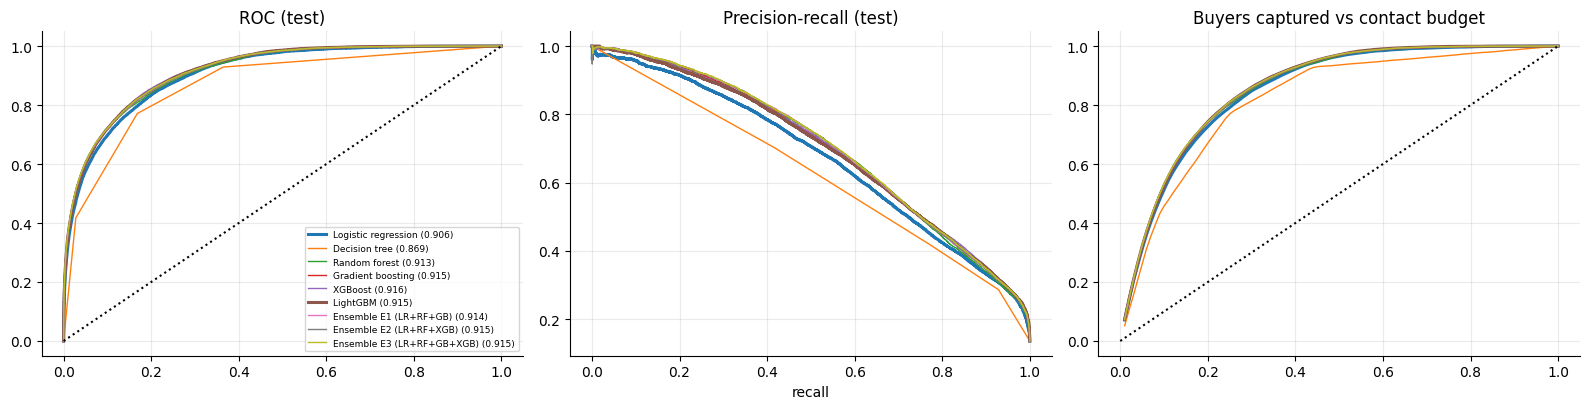

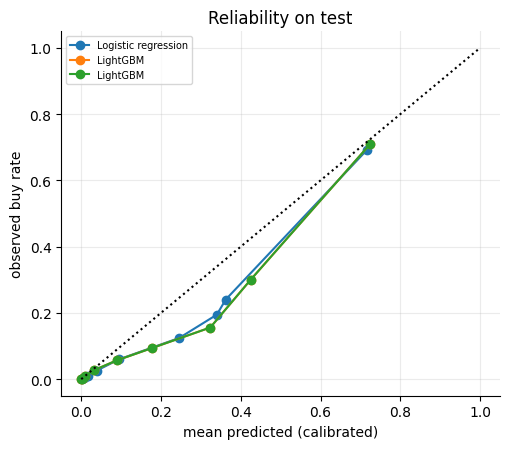

In [16]:
# curves, contact budget table, reliability tables, plots
grid = np.linspace(0, 1, 201)
roc_c, pr_c = [], []
for k in ALL:
    fpr, tpr, _ = roc_curve(yte, PT[k]); roc_c.append(pd.DataFrame({"model": NAMES[k], "fpr": grid, "tpr": np.interp(grid, fpr, tpr)}))
    pr, rc, _ = precision_recall_curve(yte, PT[k]); pr_c.append(pd.DataFrame({"model": NAMES[k], "recall": grid, "precision": np.interp(grid, rc[::-1], pr[::-1])}))
pd.concat(roc_c).to_csv(ART / "curves_roc.csv", index=False); pd.concat(pr_c).to_csv(ART / "curves_pr.csv", index=False)

qs = np.round(np.arange(0.01, 1.0001, 0.01), 2)
cb = []
for k in ALL:
    cap, prec = capture_curve(PT[k], yte, snap_te, tie_te, qs)
    cb.append(pd.DataFrame({"model": NAMES[k], "contact_share": qs, "buyers_captured": cap, "precision": prec, "lift": prec / yte.mean()}))
cb = pd.concat(cb); cb.to_csv(ART / "contact_budget.csv", index=False)

rel = []
for k in ALL:
    d = pd.DataFrame({"p": PTC[k], "y": yte}); d["bin"] = pd.qcut(d.p.rank(method="first"), 10, labels=False)
    g = d.groupby("bin").agg(mean_predicted=("p", "mean"), observed_rate=("y", "mean"), rows=("y", "size")).reset_index(); g.insert(0, "model", NAMES[k]); rel.append(g)
pd.concat(rel).to_csv(ART / "reliability_table.csv", index=False)
bt = test_metrics.set_index("key")[["brier_raw", "brier"]].join(cal_cv.assign(key=ALL).set_index("key")["chosen"])
print("test Brier raw vs calibrated:"); print(bt.round(5).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for k in ALL:
    lw = 2.2 if k in (BEST_ALL, "lr") else 1
    f, t_ = roc_curve(yte, PT[k])[:2]; ax[0].plot(f, t_, lw=lw, label=f"{NAMES[k]} ({roc_auc_score(yte, PT[k]):.3f})")
    p_, r_ = precision_recall_curve(yte, PT[k])[:2]; ax[1].plot(r_, p_, lw=lw)
    c_, pr_ = capture_curve(PT[k], yte, snap_te, tie_te, qs); ax[2].plot(qs, c_, lw=lw)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC (test)"); ax[0].legend(fontsize=6.5)
ax[1].set_title("Precision-recall (test)"); ax[1].set_xlabel("recall"); ax[2].set_title("Buyers captured vs contact budget"); ax[2].plot([0, 1], [0, 1], "k:")
save_fig("test_curves")
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for k in ("lr", BEST_SINGLE, BEST_ALL):
    g = pd.concat(rel); g = g[g.model == NAMES[k]]; ax.plot(g.mean_predicted, g.observed_rate, "o-", label=NAMES[k])
ax.plot([0, 1], [0, 1], "k:"); ax.set_xlabel("mean predicted (calibrated)"); ax.set_ylabel("observed buy rate"); ax.set_title("Reliability on test"); ax.legend(fontsize=7)
save_fig("reliability")

## 8. Rolling-origin evaluation

Two views of stability over time:
1. **Frozen models** (trained once on the training block): metrics at each of the seven test cut-offs, mean and standard deviation.
2. **True rolling origin**: for each test cut-off T the tuned configurations are **refit on every labelled snapshot whose six-month window ended before T** (expanding window, no hyper-parameter search again) and scored on the snapshot at T alone.

refit cut-off 2021-12-01: train rows 469,571, ROC-AUC LR 0.900, best-ensemble 0.906


refit cut-off 2022-02-01: train rows 521,142, ROC-AUC LR 0.895, best-ensemble 0.903


refit cut-off 2022-04-01: train rows 574,268, ROC-AUC LR 0.909, best-ensemble 0.918


refit cut-off 2022-06-01: train rows 628,920, ROC-AUC LR 0.909, best-ensemble 0.917
                        scheme                      model  roc_auc_mean  roc_auc_std  pr_auc_mean  pr_auc_std  capture_20_mean  capture_20_std
frozen models, 7 test cut-offs              Decision tree        0.8705       0.0053       0.4986      0.0237           0.6714          0.0234
frozen models, 7 test cut-offs     Ensemble E1 (LR+RF+GB)        0.9153       0.0041       0.7055      0.0194           0.7462          0.0315
frozen models, 7 test cut-offs    Ensemble E2 (LR+RF+XGB)        0.9155       0.0039       0.7055      0.0203           0.7453          0.0295
frozen models, 7 test cut-offs Ensemble E3 (LR+RF+GB+XGB)        0.9162       0.0038       0.7067      0.0200           0.7467          0.0316
frozen models, 7 test cut-offs          Gradient boosting        0.9152       0.0036       0.7011      0.0188           0.7446          0.0309
frozen models, 7 test cut-offs                   LightGBM 

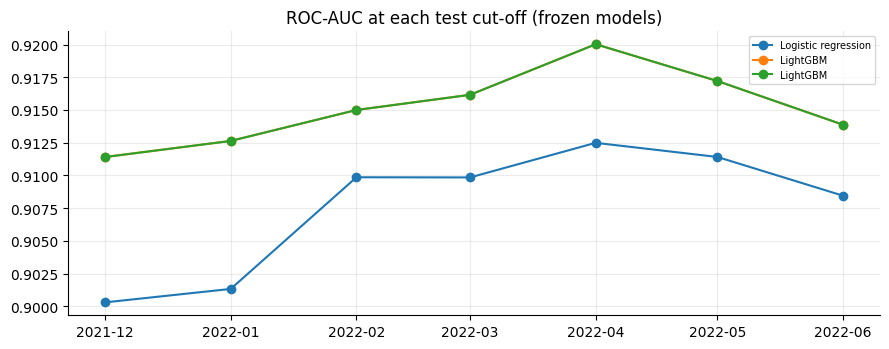

In [17]:
def per_snapshot(preds, frame):
    out = []
    for T, idx in frame.groupby("snapshot").indices.items():
        y = frame[Y].values[idx]
        for k in ALL:
            s = preds[k][idx]; c, p = capture_curve(s, y, np.zeros(len(idx), int), np.random.RandomState(SEED).rand(len(idx)), (0.2,))
            out.append(dict(cutoff=pd.Timestamp(T).date(), model=NAMES[k], key=k, positive_rate=y.mean(), roc_auc=roc_auc_score(y, s), pr_auc=average_precision_score(y, s), capture_20=c[0]))
    return pd.DataFrame(out)

frozen_roll = per_snapshot(PT, TE); frozen_roll.to_csv(ART / "frozen_by_cutoff.csv", index=False)
roll_cut = list(pd.date_range("2021-12-01", "2022-06-01", freq="2MS"))[: (4 if not SMOKE else 2)]
refit_rows = []
for Tk in roll_cut:
    tr_mask = (panel.snapshot <= Tk - pd.DateOffset(months=6)); trk = panel[tr_mask]; tek = panel[panel.snapshot == Tk].reset_index(drop=True)
    ytk, yk = trk[Y].values, tek[Y].values; pk = {}
    for nm in BASE:
        pk[nm] = proba(fit_model(nm, BEST[nm], trk, ytk, USE_CW and nm != "lr"), nm, tek)
    for e, parts in ENS.items():
        pk[e] = np.mean([pk[p] for p in parts], axis=0)
    for k in ALL:
        c, p = capture_curve(pk[k], yk, np.zeros(len(tek), int), np.random.RandomState(SEED).rand(len(tek)), (0.2,))
        refit_rows.append(dict(cutoff=Tk.date(), train_rows=len(trk), model=NAMES[k], key=k, positive_rate=yk.mean(), roc_auc=roc_auc_score(yk, pk[k]), pr_auc=average_precision_score(yk, pk[k]), capture_20=c[0]))
    print(f"refit cut-off {Tk.date()}: train rows {len(trk):,}, ROC-AUC LR {refit_rows[-9]['roc_auc']:.3f}, best-ensemble {[r for r in refit_rows[-9:] if r['key']==BEST_ALL][0]['roc_auc']:.3f}")
refit_roll = pd.DataFrame(refit_rows); refit_roll.to_csv(ART / "rolling_origin_refit.csv", index=False)
def mean_std(df, label):
    g = df.groupby(["model", "key"]).agg(**{f"{m}_{s}": (m, s) for m in MET for s in ("mean", "std")}, n_cutoffs=("cutoff", "nunique")).reset_index()
    g.insert(0, "scheme", label); return g
roll_sum = pd.concat([mean_std(frozen_roll, "frozen models, 7 test cut-offs"), mean_std(refit_roll, f"expanding refit, {len(roll_cut)} cut-offs")])
roll_sum.to_csv(ART / "rolling_origin_summary.csv", index=False)
print(roll_sum[["scheme", "model", "roc_auc_mean", "roc_auc_std", "pr_auc_mean", "pr_auc_std", "capture_20_mean", "capture_20_std"]].round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.6))
for k in ("lr", BEST_SINGLE, BEST_ALL):
    g = frozen_roll[frozen_roll.key == k]; ax.plot(pd.to_datetime(g.cutoff), g.roc_auc, "o-", label=NAMES[k])
ax.set_title("ROC-AUC at each test cut-off (frozen models)"); ax.legend(fontsize=7); save_fig("rolling_origin")

## 9. Segment analytics (wealth and retail banking view)

Scores come from the best model on **validation** (see below). The contact list is the top 20% of each cut-off by that score. For each group: uptake rate (share who buy within six months), the model's ROC-AUC inside the group, and the share of the group's buyers reached by the list.

In [18]:
HEAD = BEST_ALL
print("headline model (best validation ROC-AUC):", NAMES[HEAD])
TE["score"] = PT[HEAD]; TE["score_cal"] = PTC[HEAD]
TE["top20"] = top_masks(PT[HEAD], snap_te, (0.2,), tie_te)[0.2]
TE["segment"] = np.select([TE.seg_premium == 1, TE.seg_professional == 1, TE.seg_other == 1], ["Premium", "Professional", "Legal entity / Inactive"], "Mass")
rk = {0: "Conservative", 1: "Income", 2: "Balanced", 3: "Aggressive"}
TE["risk_profile"] = TE.risk_ord.map(rk).fillna("Not available")
TE["risk_source"] = np.where(TE.risk_missing == 1, "not available", np.where(TE.risk_predicted == 1, "predicted (simulated)", "questionnaire"))
cp_ = {0: "under 30k", 1: "30k-80k", 2: "80k-300k", 3: "over 300k"}
TE["capacity_band"] = TE.cap_ord.map(cp_).fillna("Not available")

def group_table(col):
    rows = []
    for g, d in TE.groupby(col):
        y = d[Y].values
        rows.append(dict(group=g, customers=d.customerID.nunique(), rows=len(d), uptake_rate=y.mean(), model_roc_auc=roc_auc_score(y, d.score) if 0 < y.sum() < len(y) else np.nan,
                         capture_20=y[d.top20.values].sum() / max(y.sum(), 1), precision_in_list=y[d.top20.values].mean() if d.top20.sum() else np.nan,
                         share_of_contact_list=d.top20.sum() / TE.top20.sum(), share_of_buyers=y.sum() / yte.sum()))
    return pd.DataFrame(rows)
seg_tabs = []
for col, label in (("segment", "customer segment"), ("risk_profile", "risk profile"), ("risk_source", "risk profile source"), ("capacity_band", "investment capacity")):
    t_ = group_table(col); t_.insert(0, "dimension", label); seg_tabs.append(t_)
seg_all = pd.concat(seg_tabs); seg_all.to_csv(ART / "segment_results.csv", index=False)
print("overall uptake", round(float(yte.mean()), 4), "| capture@20", round(float(yte[TE.top20.values].sum() / yte.sum()), 4))
print(seg_all.round(3).to_string(index=False))

# robustness slices: customers with and without a trade in the last 12 months
TE["active_12m"] = np.where((TE.n_buy_12m + TE.n_sell_12m) > 0, "traded in last 12 months", "no trade in last 12 months")
slice_rows = []
for g, d in TE.groupby("active_12m"):
    y = d[Y].values; idx = d.index.values
    for k in ("lr", BEST_SINGLE, HEAD):
        s = PT[k][idx]; c, p = capture_curve(s, y, np.zeros(len(d), int), np.random.RandomState(SEED).rand(len(d)), (0.2,))
        slice_rows.append(dict(slice=g, model=NAMES[k], rows=len(d), share_of_rows=len(d) / len(TE), uptake_rate=y.mean(), roc_auc=roc_auc_score(y, s), pr_auc=average_precision_score(y, s), capture_20=c[0]))
slices = pd.DataFrame(slice_rows); slices.to_csv(ART / "activity_slices.csv", index=False); print(slices.round(3).to_string(index=False))

headline model (best validation ROC-AUC): LightGBM


overall uptake 0.1357 | capture@20 0.7435
          dimension                   group  customers   rows  uptake_rate  model_roc_auc  capture_20  precision_in_list  share_of_contact_list  share_of_buyers
   customer segment Legal entity / Inactive        247   1721        0.055          0.963       0.766              0.581                  0.003            0.004
   customer segment                    Mass      18411 127736        0.090          0.932       0.715              0.507                  0.411            0.429
   customer segment                 Premium       8606  59048        0.231          0.865       0.764              0.511                  0.516            0.508
   customer segment            Professional       1304   9008        0.174          0.875       0.776              0.437                  0.070            0.059
       risk profile              Aggressive       2611  17964        0.270          0.861       0.822              0.514                  0.196          

                     slice               model   rows  share_of_rows  uptake_rate  roc_auc  pr_auc  capture_20
no trade in last 12 months Logistic regression  86022          0.436        0.028    0.845   0.125       0.707
no trade in last 12 months            LightGBM  86022          0.436        0.028    0.855   0.129       0.718
no trade in last 12 months            LightGBM  86022          0.436        0.028    0.855   0.129       0.718
  traded in last 12 months Logistic regression 111491          0.564        0.219    0.880   0.712       0.611
  traded in last 12 months            LightGBM 111491          0.564        0.219    0.891   0.737       0.625
  traded in last 12 months            LightGBM 111491          0.564        0.219    0.891   0.737       0.625


       band  rows  uptake_rate  buyers  mean_predicted  share_of_buyers   lift  share_of_rows
 5 very low 44034       0.0006      27          0.0015           0.0010 0.0045         0.2229
      4 low 36663       0.0067     246          0.0083           0.0092 0.0494         0.1856
   3 medium 37160       0.0424    1577          0.0609           0.0588 0.3127         0.1881
     2 high 46139       0.1368    6313          0.2652           0.2355 1.0083         0.2336
1 very high 33517       0.5561   18640          0.6108           0.6954 4.0982         0.1697


silhouette by k: {3: 0.377, 4: 0.389, 5: 0.406, 6: 0.303} -> k = 5


 rows  uptake_rate  mean_score  n_buy_12m  buy_val_12m  days_since_last_trade  n_assets_held  port_value_log  hhi_held  risk_ord  tenure_days  share_internet_12m  share_of_rows                                              name
40282        0.055       0.101      0.015        0.069            1065.105957          1.563           7.156     0.882     1.143  1284.615967               0.002          0.204  cluster 0: dormant, larger portfolio, lower risk
 7140        0.883       0.863     35.958       10.944              26.846001          8.335          10.067     0.323     1.878  1381.189941               0.778          0.036  cluster 1: active, larger portfolio, higher risk
29569        0.405       0.464      3.122        7.600             114.296997          3.020           8.239     0.590     1.754  1280.896973               0.591          0.150  cluster 2: active, larger portfolio, higher risk
86704        0.018       0.029      0.027        0.104             564.642029          0.000

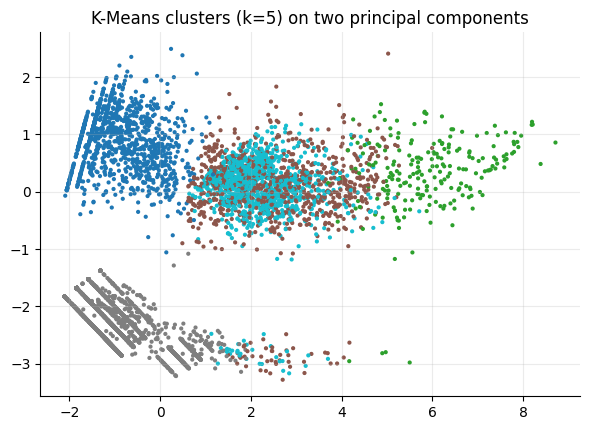

In [19]:
# five propensity bands: edges are quintiles of the calibrated validation score
edges = np.quantile(PVC[HEAD], [0.2, 0.4, 0.6, 0.8]).tolist()
jdump({"model": HEAD, "calibrated_probability_edges_from_validation": edges}, "band_edges.json")
BAND_NAMES = ["5 very low", "4 low", "3 medium", "2 high", "1 very high"]
TE["band"] = np.array(BAND_NAMES)[np.searchsorted(edges, TE.score_cal.values)]
bands = TE.groupby("band").agg(rows=(Y, "size"), uptake_rate=(Y, "mean"), buyers=(Y, "sum"), mean_predicted=("score_cal", "mean")).reset_index().sort_values("band", ascending=False)
bands["share_of_buyers"] = bands.buyers / bands.buyers.sum(); bands["lift"] = bands.uptake_rate / yte.mean(); bands["share_of_rows"] = bands.rows / len(TE)
bands.to_csv(ART / "propensity_bands.csv", index=False); print(bands.round(4).to_string(index=False))

# K-Means behavioural clusters on pre-T features
KM = ["n_buy_12m", "buy_val_12m", "days_since_last_trade", "n_assets_held", "port_value_log", "hhi_held", "risk_ord", "tenure_days", "share_internet_12m"]
def km_matrix(d):
    X = d[KM].copy(); X["risk_ord"] = X["risk_ord"].where(X["risk_ord"] >= 0, 1.5); return X.to_numpy(float)
km_tr = TR.sample(min(30000, len(TR)), random_state=SEED)
Xk = km_matrix(km_tr); lo_k, hi_k = np.percentile(Xk, 1, axis=0), np.percentile(Xk, 99, axis=0)
sc_k = StandardScaler().fit(np.clip(Xk, lo_k, hi_k)); Zk = sc_k.transform(np.clip(Xk, lo_k, hi_k))
sil_idx = np.random.RandomState(SEED).choice(len(Zk), min(8000, len(Zk)), replace=False)
sil = {}
for k_ in range(3, 7):
    lab_ = KMeans(k_, n_init=10, random_state=SEED).fit_predict(Zk); sil[k_] = float(silhouette_score(Zk[sil_idx], lab_[sil_idx]))
K_BEST = max(sil, key=sil.get); print("silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "-> k =", K_BEST)
kmeans = KMeans(K_BEST, n_init=10, random_state=SEED).fit(Zk)
TE["cluster_raw"] = kmeans.predict(sc_k.transform(np.clip(km_matrix(TE), lo_k, hi_k)))
prof = TE.groupby("cluster_raw").agg(rows=(Y, "size"), uptake_rate=(Y, "mean"), mean_score=("score_cal", "mean"), **{c: (c, "mean") for c in KM}).reset_index()
prof["share_of_rows"] = prof.rows / len(TE)
act_hi = prof.n_buy_12m > TE.n_buy_12m.mean(); port_hi = prof.port_value_log > TE.port_value_log.mean()
prof["name"] = ["cluster %d: %s, %s portfolio, %s risk" % (c, "active" if a else "dormant", "larger" if p else "smaller", "higher" if r > TE.risk_ord[TE.risk_ord >= 0].mean() else "lower")
                for c, a, p, r in zip(prof.cluster_raw, act_hi, port_hi, prof.risk_ord)]
TE["cluster"] = TE.cluster_raw.map(dict(zip(prof.cluster_raw, prof.name)))
prof.to_csv(ART / "kmeans_profiles.csv", index=False)
xt = pd.crosstab(TE.cluster, TE.segment); xt.to_csv(ART / "kmeans_vs_segment_counts.csv"); xtp = pd.crosstab(TE.cluster, TE.segment, normalize="index"); xtp.to_csv(ART / "kmeans_vs_segment_share.csv")
jdump({"k": K_BEST, "silhouette": sil, "features": KM, "clip_lo": lo_k.tolist(), "clip_hi": hi_k.tolist(), "scaler_mean": sc_k.mean_.tolist(), "scaler_scale": sc_k.scale_.tolist(),
       "centers_scaled": kmeans.cluster_centers_.tolist(), "names": dict(zip(prof.cluster_raw.astype(str), prof.name))}, "kmeans_model.json")
print(prof.drop(columns=["cluster_raw"]).round(3).to_string(index=False)); print(xtp.round(3).to_string())
pc = PCA(2, random_state=SEED).fit(Zk); zz = pc.transform(sc_k.transform(np.clip(km_matrix(TE.sample(6000, random_state=SEED)), lo_k, hi_k)))
fig, ax = plt.subplots(figsize=(6, 4.4)); ax.scatter(zz[:, 0], zz[:, 1], c=kmeans.predict(sc_k.transform(np.clip(km_matrix(TE.sample(6000, random_state=SEED)), lo_k, hi_k))), s=4, cmap="tab10")
ax.set_title(f"K-Means clusters (k={K_BEST}) on two principal components"); save_fig("kmeans_pca")

## 10. Explainability

* **Permutation importance** (XGBoost, test sample): drop in ROC-AUC when one feature is shuffled.
* **SHAP** (`TreeExplainer` on the tuned XGBoost model, test sample): mean absolute contribution to the log-odds of a buy. The direction comes from the correlation between a feature's value and its SHAP value.
* **Logistic regression coefficients** on standardised, winsorised inputs (change in log-odds per one standard deviation).

shap.TreeExplainer used; max |difference| from XGBoost's own TreeSHAP contributions: 0.0


SHAP source: shap.TreeExplainer
            feature  mean_abs_shap  direction_corr
days_since_last_buy          0.514          -0.967
     port_value_log          0.455           0.945
      cap_predicted          0.391          -0.964
           risk_ord          0.318           0.897
        share_stock          0.309           0.952
          n_buy_all          0.305           0.446
   share_branch_12m          0.258          -0.970
          n_buy_12m          0.252           0.601
           hhi_held          0.213          -0.914
        seg_premium          0.158           0.958

Top 10 drivers, plain English:
 1. Days since the last BUY trade; if there is none, the days since 2018-01-02 (at least that long). Higher values lower the chance of a buy.
 2. Log of 1 + estimated market value of holdings at T (net units times the last close, euros). Higher values raise the chance of a buy.
 3. 1 if the capacity band was estimated by an algorithm. Higher values lower the chance of a bu

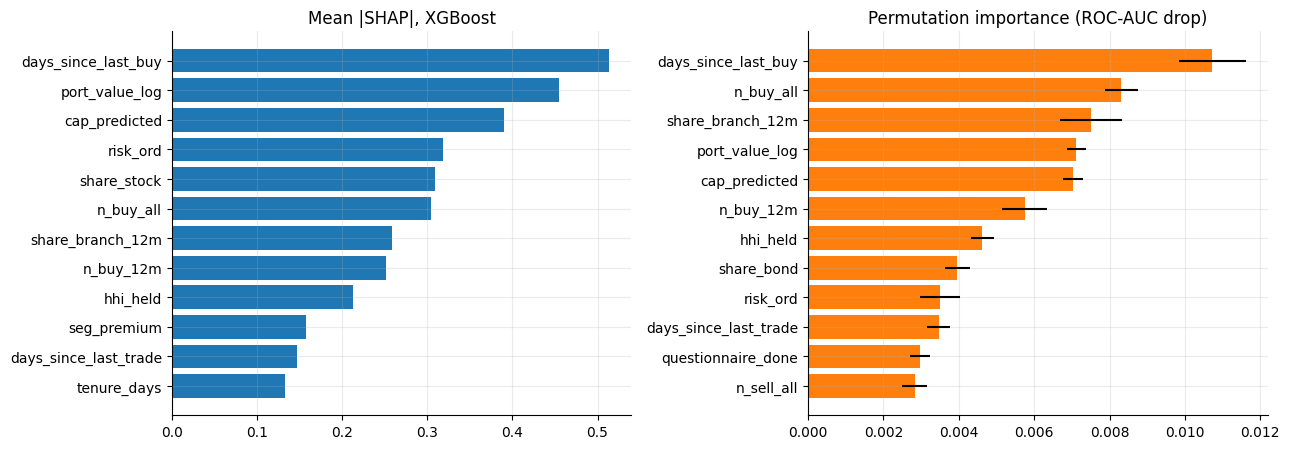

In [20]:
xg = MODELS["xgb"]
ns = min(20000, len(TE)); ix = np.random.RandomState(SEED).choice(len(TE), ns, replace=False)
pi = permutation_importance(xg, TE.iloc[ix][TREE_COLS], yte[ix], scoring="roc_auc", n_repeats=N_PERM, random_state=SEED, n_jobs=1)
perm = pd.DataFrame({"feature": TREE_COLS, "auc_drop_mean": pi.importances_mean, "auc_drop_std": pi.importances_std}).sort_values("auc_drop_mean", ascending=False)
perm["meaning"] = perm.feature.map(DESC); perm.to_csv(ART / "permutation_importance.csv", index=False)
ixs = np.random.RandomState(SEED + 7).choice(len(TE), min(N_SHAP, len(TE)), replace=False); Xsh = TE.iloc[ixs][TREE_COLS].reset_index(drop=True)
contrib = xg.get_booster().predict(xgb.DMatrix(Xsh), pred_contribs=True)[:, :-1]
try:
    import shap
    sv = shap.TreeExplainer(xg).shap_values(Xsh); sv = sv[1] if isinstance(sv, list) else sv
    print("shap.TreeExplainer used; max |difference| from XGBoost's own TreeSHAP contributions:", float(np.abs(sv - contrib).max()))
    SHAP_SRC = "shap.TreeExplainer"
except Exception as e:
    print("shap package unavailable here (", type(e).__name__, "): using XGBoost pred_contribs, which is the same TreeSHAP algorithm"); sv, SHAP_SRC = contrib, "xgboost pred_contribs"
sh = pd.DataFrame({"feature": TREE_COLS, "mean_abs_shap": np.abs(sv).mean(0),
                   "direction_corr": [np.corrcoef(Xsh[c], sv[:, i])[0, 1] if Xsh[c].std() > 0 and sv[:, i].std() > 0 else 0.0 for i, c in enumerate(TREE_COLS)]}).sort_values("mean_abs_shap", ascending=False)
sh["meaning"] = sh.feature.map(DESC)
sh["plain_english"] = [f"{DESC[f]} Higher values {'raise' if d > 0.05 else 'lower' if d < -0.05 else 'have a mixed effect on'} the chance of a buy." for f, d in zip(sh.feature, sh.direction_corr)]
sh.to_csv(ART / "shap_summary.csv", index=False)
pd.concat([Xsh.round(4), pd.DataFrame(sv.round(4), columns=[f"shap_{c}" for c in TREE_COLS])], axis=1).to_csv(ART / "shap_sample.csv.gz", index=False)
print("SHAP source:", SHAP_SRC); print(sh.head(10)[["feature", "mean_abs_shap", "direction_corr"]].round(3).to_string(index=False))
print("\nTop 10 drivers, plain English:")
for i, r in enumerate(sh.head(10).itertuples(), 1):
    print(f"{i:2d}. {r.plain_english}")
lrm = MODELS["lr"].named_steps["logisticregression"]
coef = pd.DataFrame({"feature": LR_COLS, "coef_per_sd": lrm.coef_[0], "odds_ratio_per_sd": np.exp(lrm.coef_[0])}).sort_values("coef_per_sd", key=abs, ascending=False)
coef["meaning"] = coef.feature.map(DESC); coef.to_csv(ART / "lr_coefficients.csv", index=False); print("\nLR strongest coefficients:"); print(coef.head(8).round(3)[["feature", "coef_per_sd", "odds_ratio_per_sd"]].to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
t10 = sh.head(12).iloc[::-1]; ax[0].barh(t10.feature, t10.mean_abs_shap, color="#1f77b4"); ax[0].set_title(f"Mean |SHAP|, {NAMES['xgb']}")
p10 = perm.head(12).iloc[::-1]; ax[1].barh(p10.feature, p10.auc_drop_mean, xerr=p10.auc_drop_std, color="#ff7f0e"); ax[1].set_title("Permutation importance (ROC-AUC drop)")
save_fig("drivers")

## 11. Product-category variants and ablations

* **Category variants**: the same features, label = at least one BUY of a stock / fund (MTF) / bond in the next six months. Logistic regression and the best single model on validation, with the tuned settings from section 6 (not re-tuned).
* **Ablation**: remove the 11 static customer attributes (segment, risk, capacity, questionnaire) and keep behaviour only, to see how much the models lean on attributes that are partly simulated.

In [21]:
cat_rows = []
for lab, nice in (("y_stock", "stock"), ("y_fund", "fund (MTF)"), ("y_bond", "bond")):
    yl_tr, yl_te = TR[lab].values, TE[lab].values
    for nm in ("lr", BEST_SINGLE):
        pm = proba(fit_model(nm, BEST[nm], TR, yl_tr, USE_CW and nm != "lr"), nm, TE)
        c, p = capture_curve(pm, yl_te, snap_te, tie_te, (0.2,))
        cat_rows.append(dict(category=nice, model=NAMES[nm], positive_rate_train=yl_tr.mean(), positive_rate_test=yl_te.mean(), buyers_test=int(yl_te.sum()), roc_auc=roc_auc_score(yl_te, pm), pr_auc=average_precision_score(yl_te, pm), capture_20=c[0]))
cat_df = pd.concat([pd.DataFrame([dict(category="any buy (main task)", model=NAMES[nm], positive_rate_train=ytr.mean(), positive_rate_test=yte.mean(), buyers_test=int(yte.sum()), roc_auc=roc_auc_score(yte, PT[nm]), pr_auc=average_precision_score(yte, PT[nm]),
                    capture_20=test_metrics.set_index("key").loc[nm, "capture_20"]) for nm in ("lr", BEST_SINGLE)]), pd.DataFrame(cat_rows)])
cat_df.to_csv(ART / "category_variants.csv", index=False); print(cat_df.round(4).to_string(index=False))

COLS_FULL = {k: list(v) for k, v in COLS.items()}
abl = []
for nm in ("lr", BEST_SINGLE, "xgb"):
    if nm in [a["key"] for a in abl]:
        continue
    COLS.update({k: [c for c in v if c not in STATIC] for k, v in COLS_FULL.items()})
    pm = proba(fit_model(nm, BEST[nm], TR, ytr, USE_CW and nm != "lr"), nm, TE)
    COLS.update(COLS_FULL)
    c, p = capture_curve(pm, yte, snap_te, tie_te, (0.2,)); c0 = test_metrics.set_index("key").loc[nm]
    abl.append(dict(key=nm, model=NAMES[nm], roc_auc_all_features=c0.roc_auc, roc_auc_behaviour_only=roc_auc_score(yte, pm), pr_auc_all_features=c0.pr_auc, pr_auc_behaviour_only=average_precision_score(yte, pm),
                    capture_20_all_features=c0.capture_20, capture_20_behaviour_only=c[0]))
abl = pd.DataFrame(abl); abl.to_csv(ART / "ablation_static_attributes.csv", index=False); print(abl.round(4).to_string(index=False))

           category               model  positive_rate_train  positive_rate_test  buyers_test  roc_auc  pr_auc  capture_20
any buy (main task) Logistic regression               0.1675              0.1357        26803   0.9064  0.6715      0.7270
any buy (main task)            LightGBM               0.1675              0.1357        26803   0.9148  0.6961      0.7435
              stock Logistic regression               0.1559              0.1043        20593   0.9463  0.7313      0.8730
              stock            LightGBM               0.1559              0.1043        20593   0.9533  0.7610      0.8850
         fund (MTF) Logistic regression               0.0085              0.0074         1456   0.8408  0.0398      0.6841
         fund (MTF)            LightGBM               0.0085              0.0074         1456   0.8480  0.0459      0.7143
               bond Logistic regression               0.0084              0.0293         5794   0.9006  0.1999      0.8661
               b

 key               model  roc_auc_all_features  roc_auc_behaviour_only  pr_auc_all_features  pr_auc_behaviour_only  capture_20_all_features  capture_20_behaviour_only
  lr Logistic regression                0.9064                  0.9064               0.6715                 0.6785                   0.7270                     0.7319
lgbm            LightGBM                0.9148                  0.9073               0.6961                 0.6876                   0.7435                     0.7361
 xgb             XGBoost                0.9157                  0.9097               0.6998                 0.6939                   0.7419                     0.7416


## 12. Freeze models and scored tables

The six tuned models (fitted on the training block only) are saved. XGBoost is saved in its own JSON format, the others with joblib. Ensembles are not saved as objects: they are the plain average of their components' probabilities (definition in `models/manifest.json`). The app and the tests read only these files.

In [22]:
for nm in BASE:
    if nm == "xgb":
        MODELS["xgb"].save_model(str(ART / "models" / "xgb.json"))
    else:
        joblib.dump(MODELS[nm], ART / "models" / f"{nm}.joblib", compress=3)
manifest = {"tree_columns": TREE_COLS, "lr_columns": LR_COLS, "ensembles": ENS, "base_models": BASE, "names": NAMES, "best_single": BEST_SINGLE, "best_ensemble": BEST_ENS, "headline_model": HEAD,
            "calibration_file": "calibration.json", "band_edges_file": "band_edges.json", "band_names_low_to_high": BAND_NAMES,
            "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "lightgbm": lightgbm.__version__, "numpy": np.__version__, "pandas": pd.__version__}}
jdump(manifest, "models/manifest.json")
fdict = pd.DataFrame([{"feature": f, "group": FD[f][0], "description": FD[f][1], "static_customer_attribute": f in STATIC, "used_by_tree_models": f in TREE_COLS, "used_by_logistic_regression": f in LR_COLS} for f in FEATURES_ALL])
fdict.to_csv(ART / "feature_dictionary.csv", index=False); print(fdict.groupby("group").size().to_dict())

out = TE[["customerID", "snapshot", "y_any", "y_stock", "y_fund", "y_bond", "segment", "risk_profile", "capacity_band", "band", "cluster"]].copy()
out["snapshot"] = out.snapshot.dt.date
for k in ALL:
    out[f"p_{k}"] = PT[k].round(5)
out["p_cal_headline"] = PTC[HEAD].round(5)
out.to_csv(ART / "test_scores.csv.gz", index=False)

latest_T = TE.snapshot.max(); L = TE[TE.snapshot == latest_T]
lat = L[["customerID", "snapshot", Y, "segment", "risk_profile", "capacity_band", "band", "cluster"] + FEATURES_ALL].copy(); lat["snapshot"] = lat.snapshot.dt.date
for k in ALL:
    lat[f"p_{k}"] = PT[k][L.index.values].round(5)
lat["p_cal_headline"] = PTC[HEAD][L.index.values].round(5)
lat.to_csv(ART / "latest_snapshot.csv.gz", index=False)
print("test_scores.csv.gz rows", len(out), "| latest_snapshot.csv.gz rows", len(lat), "cut-off", latest_T.date())

# reload the saved models and confirm they reproduce the stored scores
chk = {}
for nm in BASE:
    if nm == "xgb":
        m = xgb.XGBClassifier(); m.load_model(str(ART / "models" / "xgb.json"))
    else:
        m = joblib.load(ART / "models" / f"{nm}.joblib")
    chk[nm] = float(np.abs(proba(m, nm, L) - PT[nm][L.index.values]).max())
print("max abs difference, reloaded model vs stored score (latest cut-off):", {k: f"{v:.2e}" for k, v in chk.items()})
assert max(chk.values()) < 1e-5

{'capacity': 3, 'channel': 2, 'concentration': 2, 'diversity': 1, 'frequency': 8, 'holdings': 8, 'market context': 2, 'monetary': 4, 'questionnaire': 2, 'recency': 4, 'risk profile': 3, 'segment': 3, 'tenure': 1, 'trend': 4}


test_scores.csv.gz rows 197513 | latest_snapshot.csv.gz rows 28568 cut-off 2022-06-01


max abs difference, reloaded model vs stored score (latest cut-off): {'lr': '4.16e-17', 'dt': '0.00e+00', 'rf': '4.44e-16', 'gb': '0.00e+00', 'xgb': '0.00e+00', 'lgbm': '0.00e+00'}


## 13. Appendix (optional): next-asset recommendation for buyers

**Not part of the headline result.** Question: given that a customer buys in the next six months, can a ranker put the assets they buy in the top 10?
* Buyers at cut-off T (customers with at least one BUY in [T, T + 6 months)); candidates are the assets bought by someone in the 12 months before T that have a price at T. Ground truth: all assets the buyer buys in the window (assets outside the candidate list count as misses).
* Rankers: **global popularity** (BUYs per asset in the last 3 months), **personal history** (the customer's own past BUY count of the asset, popularity as tie-break), and a **gradient-boosting pair ranker** (scikit-learn GB on customer-asset pairs: asset popularity and returns, category, customer's holdings and history, segment, risk).
* Training cut-offs 2020-04, 2020-07, 2020-10; test cut-offs 2021-12, 2022-03, 2022-06 (a sample of buyers each). Hit@10 = share of buyers with at least one true asset in the top 10; nDCG@10 with binary relevance.
* Protocol A allows repeat purchases (what the bank would see). Protocol B counts only assets the customer never bought before T (true discovery).
* **Comparison with the paper is descriptive only.** The paper (Table 3) reports nDCG@10 of 0.2710 for popularity and 0.3404 for LightGCN, averaged over 61 two-week time points from 1 August 2019 and over all customers with a test purchase, with its own candidate set and handling of repeat purchases. This notebook uses three cut-offs, a sample of buyers, a candidate list limited to recently bought assets, and a smaller model; the numbers are not comparable and no claim is made to beat the paper.

In [23]:
N_REC_TR, N_REC_TE = (400, 1000) if not SMOKE else (80, 150)
REC_TR = ["2020-04-01", "2020-07-01", "2020-10-01"]; REC_TE = ["2021-12-01", "2022-03-01", "2022-06-01"]
PAIR_FEATS = ["pop3", "pop12", "ret3", "ret1", "vol60", "is_stock", "is_bond", "is_fund", "held", "past_buys", "cust_cat_share", "cust_n_held", "cust_port", "cust_n_buy_12m", "cust_premium", "cust_risk"]

def rec_snapshot(T, n_buyers, seed):
    T = pd.Timestamp(T); dT = dayn(T); d3, d12 = dayn(T - pd.DateOffset(months=3)), dayn(T - pd.DateOffset(months=12)); d_end = dayn(T + pd.DateOffset(months=6))
    k = int(np.searchsorted(A["day"], dT)); cid, isn, buy, day, opn, units = (A[c][:k] for c in ("cid", "isn", "buy", "day", "opn", "units"))
    ev = ~opn
    pop3 = np.bincount(isn[buy & ev & (day >= d3)], minlength=NI).astype(float); pop12 = np.bincount(isn[buy & ev & (day >= d12)], minlength=NI).astype(float)
    pT, p3, p1 = price_row(T), price_row(T - pd.DateOffset(months=3)), price_row(T - pd.DateOffset(months=1))
    ret3 = np.nan_to_num(np.clip(pT / p3 - 1, -0.9, 5)); ret1 = np.nan_to_num(np.clip(pT / p1 - 1, -0.9, 5))
    i = dayn(T) - 1 - PRICE_DAY0; w = PRICE[max(i - 60, 0): i + 1]; vol = np.nan_to_num(np.nanstd(np.diff(np.log(w), axis=0), axis=0))
    cand = np.flatnonzero((pop12 >= 1) & np.isfinite(pT))
    kb, cb_ = np.unique((cid * NI + isn)[buy], return_counts=True)
    key_all = cid * NI + isn; uk, inv = np.unique(key_all, return_inverse=True)
    net = np.bincount(inv, weights=np.where(buy, units, -units), minlength=len(uk)); held_keys = uk[net > 1e-6]
    df = panel[panel.snapshot == T]; buyers = df[df[Y] == 1]
    buyers = buyers.sample(min(n_buyers, len(buyers)), random_state=seed).reset_index(drop=True)
    c_idx = cid_map.loc[buyers.customerID].values; nb, nc = len(buyers), len(cand)
    wm = A["buy"] & (A["day"] >= dT) & (A["day"] < d_end); wkeys = np.unique(A["cid"][wm] * NI + A["isn"][wm])
    keys = (c_idx[:, None] * NI + cand[None, :]).ravel()
    pos = np.clip(np.searchsorted(kb, keys), 0, max(len(kb) - 1, 0)); past = np.where(kb[pos] == keys, cb_[pos], 0) if len(kb) else np.zeros(len(keys), int)
    held = np.isin(keys, held_keys).astype(float); truth = np.isin(keys, wkeys)
    cat_c = CAT_OF_ISIN[cand]; cs = np.stack([buyers.share_stock.values, buyers.share_bond.values, buyers.share_fund.values], 1)
    X = pd.DataFrame({"pop3": np.tile(pop3[cand], nb), "pop12": np.tile(pop12[cand], nb), "ret3": np.tile(ret3[cand], nb), "ret1": np.tile(ret1[cand], nb), "vol60": np.tile(vol[cand], nb),
                      "is_stock": np.tile(cat_c == 0, nb).astype(float), "is_bond": np.tile(cat_c == 1, nb).astype(float), "is_fund": np.tile(cat_c == 2, nb).astype(float),
                      "held": held, "past_buys": past.astype(float), "cust_cat_share": cs[:, cat_c].ravel(), "cust_n_held": np.repeat(buyers.n_assets_held.values, nc),
                      "cust_port": np.repeat(buyers.port_value_log.values, nc), "cust_n_buy_12m": np.repeat(buyers.n_buy_12m.values, nc),
                      "cust_premium": np.repeat(buyers.seg_premium.values, nc), "cust_risk": np.repeat(buyers.risk_ord.values, nc)})[PAIR_FEATS]
    wc, wi = wkeys // NI, wkeys % NI
    cnt_all = pd.Series(wc).value_counts(); new_mask = ~np.isin(wkeys, kb); cnt_new = pd.Series(wc[new_mask]).value_counts()
    return dict(X=X, y=truth.astype(int), nb=nb, nc=nc, n_truth=cnt_all.reindex(c_idx).fillna(0).values.astype(int), n_truth_new=cnt_new.reindex(c_idx).fillna(0).values.astype(int))

def rank_eval(S, Ym, n_truth, seed=0):
    S = S + 1e-9 * np.random.RandomState(seed).rand(*S.shape); keep = n_truth > 0
    S, Ym, n_truth = S[keep], Ym[keep], n_truth[keep]
    top = np.argsort(-S, axis=1)[:, :10]; rel = np.take_along_axis(Ym, top, 1)
    disc = 1 / np.log2(np.arange(2, 12)); dcg = (rel * disc).sum(1); idcg = np.cumsum(disc)[np.minimum(n_truth, 10) - 1]
    return float(rel.any(1).mean()), float((dcg / idcg).mean()), int(keep.sum())

t = time.time()
tr_parts = [rec_snapshot(T, N_REC_TR, SEED + i) for i, T in enumerate(REC_TR)]
Xr = pd.concat([p["X"] for p in tr_parts], ignore_index=True); yr = np.concatenate([p["y"] for p in tr_parts])
print(f"ranker training pairs: {len(Xr):,}, positive pairs {int(yr.sum()):,}")
rk_gb = GradientBoostingClassifier(n_estimators=120, max_depth=4, learning_rate=0.1, subsample=0.5, min_samples_leaf=100, random_state=SEED).fit(Xr, yr)
rec_rows = []
for T_i, T in enumerate(REC_TE):
    p = rec_snapshot(T, N_REC_TE, SEED + 100 + T_i); nb, nc = p["nb"], p["nc"]; X = p["X"]
    sc = {"Popularity (3 months)": X.pop3.values.reshape(nb, nc), "Personal history + popularity": (X.past_buys.values * 1000 + X.pop3.values).reshape(nb, nc),
          "Gradient-boosting pair ranker": rk_gb.predict_proba(X)[:, 1].reshape(nb, nc)}
    Ym = p["y"].reshape(nb, nc).astype(bool); newm = (X.past_buys.values == 0).reshape(nb, nc)
    for name, S in sc.items():
        h, n_, cnt = rank_eval(S, Ym, p["n_truth"]); rec_rows.append(dict(protocol="A: repeat purchases allowed", cutoff=T, model=name, hit_at_10=h, ndcg_at_10=n_, buyers_evaluated=cnt))
        if name.startswith("Personal"):
            continue                                                  # with past purchases excluded it is identical to popularity
        Sb = np.where(newm, S, -1e9); h, n_, cnt = rank_eval(Sb, Ym & newm, p["n_truth_new"]); rec_rows.append(dict(protocol="B: new assets only", cutoff=T, model=name, hit_at_10=h, ndcg_at_10=n_, buyers_evaluated=cnt))
rec = pd.DataFrame(rec_rows); rec.to_csv(ART / "rec_appendix_by_cutoff.csv", index=False)
rec_sum = rec.groupby(["protocol", "model"]).agg(hit_at_10=("hit_at_10", "mean"), ndcg_at_10=("ndcg_at_10", "mean"), buyers_evaluated=("buyers_evaluated", "sum")).reset_index()
rec_sum["paper_reference_ndcg_at_10"] = rec_sum.model.map({"Popularity (3 months)": 0.2710}); rec_sum.to_csv(ART / "rec_appendix_summary.csv", index=False)
print(rec_sum.round(4).to_string(index=False)); print(f"appendix runtime {time.time()-t:.0f}s")
print("Paper (different protocol, descriptive only): popularity nDCG@10 0.2710, LightGCN 0.3404.")

ranker training pairs: 246,800, positive pairs 3,804


                   protocol                         model  hit_at_10  ndcg_at_10  buyers_evaluated  paper_reference_ndcg_at_10
A: repeat purchases allowed Gradient-boosting pair ranker     0.7123      0.4740              3000                         NaN
A: repeat purchases allowed Personal history + popularity     0.7120      0.4609              3000                         NaN
A: repeat purchases allowed         Popularity (3 months)     0.5893      0.2582              3000                       0.271
         B: new assets only Gradient-boosting pair ranker     0.3619      0.1728              1818                         NaN
         B: new assets only         Popularity (3 months)     0.3568      0.1500              1818                       0.271
appendix runtime 41s
Paper (different protocol, descriptive only): popularity nDCG@10 0.2710, LightGCN 0.3404.


## 14. Run summary

In [24]:
tm = test_metrics.set_index("key")
summary = {"runtime_seconds": round(time.time() - T0), "smoke": SMOKE, "versions": manifest["versions"], "strategy": STRATEGY,
           "panel": {"rows": int(len(panel)), "snapshots": int(len(snap_dates)), "features_total": len(FEATURES_ALL), "features_tree": len(TREE_COLS), "features_lr": len(LR_COLS)},
           "best_single": BEST_SINGLE, "best_ensemble": BEST_ENS, "headline_model": HEAD, "n_boot": N_BOOT, "n_test_rows": int(len(TE)), "n_test_customers": int(TE.customerID.nunique()),
           "test_positive_rate": float(yte.mean()), "shap_source": SHAP_SRC, "kmeans_k": K_BEST,
           "test_roc_auc": {k: float(tm.loc[k, "roc_auc"]) for k in ALL}, "test_capture_20": {k: float(tm.loc[k, "capture_20"]) for k in ALL}}
jdump(summary, "run_summary.json")
print(json.dumps(summary, indent=1)[:1500])
print("artifacts:", sorted(p.name for p in ART.iterdir()))
print(f"total runtime {time.time()-T0:.0f}s")

{
 "runtime_seconds": 4772,
 "smoke": false,
 "versions": {
  "python": "3.13.18",
  "scikit-learn": "1.6.1",
  "xgboost": "3.4.1",
  "lightgbm": "4.6.0",
  "numpy": "2.1.3",
  "pandas": "2.3.3"
 },
 "strategy": "none",
 "panel": {
  "rows": 798812,
  "snapshots": 33,
  "features_total": 47,
  "features_tree": 37,
  "features_lr": 33
 },
 "best_single": "lgbm",
 "best_ensemble": "e3",
 "headline_model": "lgbm",
 "n_boot": 1000,
 "n_test_rows": 197513,
 "n_test_customers": 28568,
 "test_positive_rate": 0.1357024600912345,
 "shap_source": "shap.TreeExplainer",
 "kmeans_k": 5,
 "test_roc_auc": {
  "lr": 0.9064327378110001,
  "dt": 0.8689699356871337,
  "rf": 0.9125394206738168,
  "gb": 0.9145918337732948,
  "xgb": 0.915741140816964,
  "lgbm": 0.9147855639067469,
  "e1": 0.9144406651723542,
  "e2": 0.9147218366763619,
  "e3": 0.9154362643520296
 },
 "test_capture_20": {
  "lr": 0.7270081707271574,
  "dt": 0.6709696675745253,
  "rf": 0.7419318732977652,
  "gb": 0.7413722344513674,
  "xgb": 